In [ ]:
!pip install ucimlrepo

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


UCI Repo Import including all derived features

In [ ]:
from ucimlrepo import fetch_ucirepo
import pandas as pd

# fetch dataset
phiusiil_phishing_url_website = fetch_ucirepo(id=967)

# data (as pandas dataframes)
X = phiusiil_phishing_url_website.data.features
y = phiusiil_phishing_url_website.data.targets

data = pd.concat([X, y], axis=1)

# metadata
print(phiusiil_phishing_url_website.metadata)

# variable information
print(phiusiil_phishing_url_website.variables)

{'uci_id': 967, 'name': 'PhiUSIIL Phishing URL (Website)', 'repository_url': 'https://archive.ics.uci.edu/dataset/967/phiusiil+phishing+url+dataset', 'data_url': 'https://archive.ics.uci.edu/static/public/967/data.csv', 'abstract': 'PhiUSIIL Phishing URL Dataset is a substantial dataset comprising 134,850 legitimate and 100,945 phishing URLs. Most of the URLs we analyzed, while constructing the dataset, are the latest URLs. Features are extracted from the source code of the webpage and URL. Features such as CharContinuationRate, URLTitleMatchScore, URLCharProb, and TLDLegitimateProb are derived from existing features.', 'area': 'Computer Science', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 235795, 'num_features': 54, 'feature_types': ['Real', 'Categorical', 'Integer'], 'demographics': [], 'target_col': ['label'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2024, 'last_updated': 'Sun May 12 

In [ ]:
# dataset uses "label" = 1 if legitimate and "label" = 0 if phishing site.
# changing to "label" = 0 if legitimate and "label" = 1 if phishing site.

data['label'] = data['label'].map({0: 1, 1: 0})

"label" = 0 is a legitimate website. "label" = 1 is a phishing site.

In [ ]:
# pre-processing steps

# scores calculated after downloading webpage HTML
webpage_features_to_drop = [
    'LineOfCode', 'LargestLineLength', 'HasTitle',
    'HasFavicon', 'Robots', 'IsResponsive',
    'NoOfURLRedirect', 'NoOfSelfRedirect', 'HasDescription', 'NoOfPopup',
    'NoOfiFrame', 'HasExternalFormSubmit', 'HasSocialNet', 'HasSubmitButton',
    'HasHiddenFields', 'HasPasswordField', 'Bank', 'Pay', 'Crypto',
    'HasCopyrightInfo', 'NoOfImage', 'NoOfCSS', 'NoOfJS', 'NoOfSelfRef',
    'NoOfEmptyRef', 'NoOfExternalRef'
]

# derived features from URL
derived_features_to_drop = [
    'CharContinuationRate',
    'URLSimilarityIndex',
    'URLTitleMatchScore',
    'URLCharProb',
    'TLDLegitimateProb',
    'DomainTitleMatchScore'
]

# non-numeric features
columns_to_drop_num = ['label', 'URL', 'Domain', 'TLD', 'Title']

# non_numeric features + webpage scores
columns_to_drop_num.extend(webpage_features_to_drop)
columns_to_drop_num.extend(derived_features_to_drop)

PhishOFE Dataset Mounting and Pre-processing

In [ ]:
phishofe_path = '/content/drive/MyDrive/Phishing_Analysis/PhishOFE_ds.csv'
phishofe_data = pd.read_csv(phishofe_path)

print("PhishOFE Dataset Head:")
display(phishofe_data.head())

X_phishofe = phishofe_data['URL']
y_phishofe = phishofe_data['label']

print(f"Total URLs in PhishOFE dataset: {len(X_phishofe)}")

# lowercase all URLs from PhiUSIIL data
phiusiil_urls = set(data['URL'].dropna().astype(str).str.lower())

# boolean mask to check if PhishOFE entry exists in PhiUSIIL
overlap_mask = phishofe_data['URL'].astype(str).str.lower().apply(lambda x: x in phiusiil_urls)

# remove overlapping rows
phishofe_data_clean = phishofe_data[~overlap_mask].copy()

# assign X and y
X_phishofe_clean = phishofe_data_clean['URL']
y_phishofe_clean = phishofe_data_clean['label']

print(f"Original PhishOFE size: {len(phishofe_data):,}")
print(f"Cleaned PhishOFE size:  {len(phishofe_data_clean):,}")
print(f"Removed {len(phishofe_data) - len(phishofe_data_clean):,} overlapping URLs.")
print("-" * 35)

PhishOFE Dataset Head:


,URL,IsHTTPS,IsDomainIP,TLD,URLLength,NoOfSubDomain,NoOfDots,NoOfObfuscatedChar,NoOfEqual,NoOfQmark,...,HasKeywordPay,HasKeywordCrypto,NoOfPopup,NoOfiFrame,NoOfImage,NoOfJS,NoOfCSS,NoOfURLRedirect,NoOfHyperlink,label
0,https://www.fow.kr,1,0,kr,18,1,2,0,0,0,...,0,0,0,0,81,16,2,2,57,0
1,https://www.visa.com.ar,1,0,ar,23,2,3,0,0,0,...,1,0,0,0,11,31,10,0,11,0
2,https://www.inflibnet.ac.in,1,0,in,27,2,3,0,0,0,...,0,0,0,1,42,26,10,0,229,0
3,https://www.lyrsense.com,1,0,com,24,1,2,0,0,0,...,0,0,0,0,106,14,1,1,331,0
4,https://www.61saat.com,1,0,com,22,1,2,0,0,0,...,0,0,1,1,79,46,4,0,275,0


Total URLs in PhishOFE dataset: 101063
Original PhishOFE size: 101,063
Cleaned PhishOFE size:  90,980
Removed 10,083 overlapping URLs.
-----------------------------------


In [ ]:
# define and verify pipeline for extracting TLD_LEGITIMATE_PROB features

import re, numpy as np, pandas as pd

TLD_LEGITIMATE_PROB = data.groupby(data['TLD'].astype(str))['TLDLegitimateProb'].first().to_dict()
assert (data.groupby(data['TLD'].astype(str))['TLDLegitimateProb'].nunique() > 1).sum() == 0

_U    = data['URL'].astype(str)
_CHOP = (data['URLLength'].values == _U.str.len().values - 1)

def _strip_for_prob(u):
    s = u.replace('https://', '').replace('http://', '')
    if s.find('www.') == 0: s = s.replace('www.', '')
    return s

def _bins(s):
    v = np.zeros(37); n = 0
    for ch in s:
        o = ord(ch)
        if   97 <= o <= 122: i = o % 97
        elif 48 <= o <=  57: i = 26 + o % 48
        elif o == 95:        i = 36
        else:                continue
        v[i] += 1; n += 1
    return v, n

_S = [_strip_for_prob(u)[:-1] if c else _strip_for_prob(u) for u, c in zip(_U, _CHOP)]
_M = np.zeros((len(_S), 37)); _N = np.zeros(len(_S))
for k, s in enumerate(_S):
    _M[k], _N[k] = _bins(s)

_y  = data['URLCharProb'].values
_ok = (_N > 0) & np.isfinite(_y)
_A  = _M[_ok] / _N[_ok][:, None]
CHAR_PROB, *_ = np.linalg.lstsq(_A, _y[_ok], rcond=None)
CHAR_PROB = np.clip(CHAR_PROB, 0, None)

_res = _A @ CHAR_PROB - _y[_ok]
print(f'URLCharProb  R2 = {1 - (_res**2).sum() / ((_y[_ok] - _y[_ok].mean())**2).sum():.6f}')
print(f'CHAR_PROB sums to {CHAR_PROB.sum():.7f}   (never imposed - it fell out)')
print(f'TLD table: {len(TLD_LEGITIMATE_PROB)} entries')

URLCharProb  R2 = 1.000000
CHAR_PROB sums to 1.0000107   (never imposed - it fell out)
TLD table: 695 entries


In [ ]:
# extract features

_LETTER = re.compile(r'[A-Za-z]'); _DIGIT = re.compile(r'[0-9]')
_PCT         = re.compile(r'%([0-9A-Fa-f]{2})')   # capture the hex pair
_NETLOC_END  = re.compile(r'[/?#]')               # netloc ends at / ? OR #
_IPV4_PREFIX = re.compile(r'^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}')   # UNANCHORED

FEATURE_ORDER = ['Domain','DomainLength','TLD','TLDLength','URLLength','IsDomainIP',
    'NoOfSubDomain','HasObfuscation','NoOfObfuscatedChar','ObfuscationRatio',
    'NoOfLettersInURL','LetterRatioInURL','NoOfDegitsInURL','DegitRatioInURL',
    'NoOfEqualsInURL','NoOfQMarkInURL','NoOfAmpersandInURL',
    'NoOfOtherSpecialCharsInURL','SpacialCharRatioInURL','IsHTTPS',
    'CharContinuationRate','TLDLegitimateProb','URLCharProb']

def _char_continuation_rate(s):
    n = len(s)
    if n == 0: return 0.0
    chC = nmC = spC = maxCh = maxNm = maxSp = 0
    for ch in s:
        if ch.isalpha():
            chC += 1
            if   nmC > 0: maxNm = max(maxNm, nmC)
            elif spC > 0: maxSp = max(maxSp, spC)
            nmC = spC = 0
        elif ch.isdigit():
            nmC += 1
            if   chC > 0: maxCh = max(maxCh, chC)
            elif spC > 0: maxSp = max(maxSp, spC)
            chC = spC = 0
        else:
            spC += 1
            if   nmC > 0: maxNm = max(maxNm, nmC)
            elif chC > 0: maxCh = max(maxCh, chC)
            nmC = chC = 0
    return (max(maxCh, chC) + max(maxNm, nmC) + max(maxSp, spC)) / n

def _root_domain(domain):
    s = domain.replace('https://', '').replace('http://', '')
    if s.find('www.') == 0: s = s.replace('www.', '')
    i = s.rfind('.')
    return s[:i] if i != -1 else ''     # '' when replace-all ate every dot

def _url_char_prob(s):
    t = 0.0; n = 0
    for ch in s:
        o = ord(ch)
        if   97 <= o <= 122: i = o % 97
        elif 48 <= o <=  57: i = 26 + o % 48
        elif o == 95:        i = 36
        else:                continue
        t += CHAR_PROB[i]; n += 1
    return t / n if n else 0.0

def extract_url_features(url, chop=True):
    url    = '' if url is None else str(url).strip()
    after  = url.split('://', 1)[1] if '://' in url else url
    domain = _NETLOC_END.split(after)[0]          # not just split('/')
    labels = domain.split('.')
    tld    = labels[-1] if len(labels) > 1 else ''

    # counts use replace-ALL www.
    s = url.replace('https://', '').replace('http://', '').replace('www.', '')
    if chop: s = s[:-1]

    # URLCharProb alone uses CONDITIONAL www. stripping
    sp = url.replace('https://', '').replace('http://', '')
    if sp.find('www.') == 0: sp = sp.replace('www.', '')
    if chop: sp = sp[:-1]

    url_length = max(len(url) - 1, 0) if chop else len(url)
    denom = url_length or 1

    n_obf = 3 * sum(1 for h in _PCT.findall(s) if 32 <= int(h, 16) < 127)  # skip non-ASCII
    nl = len(_LETTER.findall(s)); nd = len(_DIGIT.findall(s))
    ne = s.count('='); nq = s.count('?')
    na = s.count('%')          # NOT '&' -- the column is mislabelled
    no = len(s) - nl - nd - ne - nq - na

    return {
        'Domain': domain, 'DomainLength': len(domain),
        'TLD': tld, 'TLDLength': len(tld), 'URLLength': url_length,
        'IsDomainIP': int(bool(_IPV4_PREFIX.match(domain))),
        'NoOfSubDomain': max(domain.count('.') - 1, 0) if len(labels) > 1 else 0,
        'HasObfuscation': int(n_obf > 0), 'NoOfObfuscatedChar': n_obf,
        'ObfuscationRatio': round(n_obf / denom, 3),
        'NoOfLettersInURL': nl, 'LetterRatioInURL': round(nl / denom, 3),
        'NoOfDegitsInURL': nd,  'DegitRatioInURL':  round(nd / denom, 3),
        'NoOfEqualsInURL': ne, 'NoOfQMarkInURL': nq, 'NoOfAmpersandInURL': na,
        'NoOfOtherSpecialCharsInURL': no,
        'SpacialCharRatioInURL': round((ne + nq + na + no) / denom, 3),
        'IsHTTPS': int('https' in url.lower()),
        'CharContinuationRate': _char_continuation_rate(_root_domain(domain)),
        'TLDLegitimateProb': TLD_LEGITIMATE_PROB.get(tld, 0.0),
        'URLCharProb': _url_char_prob(sp),
    }

def extract_url_features_batch(urls, chop=True):
    urls = pd.Series(urls)
    if len(urls) == 0:
        return pd.DataFrame(columns=FEATURE_ORDER, index=urls.index)
    return pd.DataFrame([extract_url_features(u, chop) for u in urls],
                        index=urls.index)[FEATURE_ORDER]

In [ ]:
# validate against PhiUSIIL

def validate_against_phiusiil(df, url_col='URL', chop=True, n_samples=3):
    """chop='oracle' recovers the per-row flag from the dataset's own URLLength,
    separating 'are the conventions right' from 'is the off-by-one predictable'."""
    urls = df[url_col].astype(str)
    if chop == 'oracle':
        flag = (df['URLLength'].values == urls.str.len().values - 1)
        rec  = [extract_url_features(u, bool(c)) for u, c in zip(urls, flag)]
        recomputed = pd.DataFrame(rec, index=urls.index)[FEATURE_ORDER]
    else:
        recomputed = extract_url_features_batch(urls, chop)

    rows, samples = [], []
    for col in [c for c in recomputed.columns if c in df.columns]:
        got, exp = recomputed[col], df[col]
        if pd.api.types.is_numeric_dtype(exp) and pd.api.types.is_numeric_dtype(got):
            match = np.isclose(got.values.astype(float), exp.values.astype(float),
                               rtol=0, atol=5e-4, equal_nan=True)
        else:
            match = got.astype(str).values == exp.astype(str).values
        rows.append({'feature': col, 'n_mismatches': int((~match).sum()),
                     'n_total': len(match), 'match_rate': match.mean()})
        for i in df.index[~match][:n_samples]:
            samples.append({'feature': col, 'URL': df.at[i, url_col],
                            'expected': exp.at[i], 'got': got.at[i]})
    return (pd.DataFrame(rows).set_index('feature').sort_values('match_rate'),
            pd.DataFrame(samples))

report, samples = validate_against_phiusiil(data, chop='oracle')
print(report.to_string())

                            n_mismatches  n_total  match_rate
feature                                                      
ObfuscationRatio                     449   235795    0.998096
NoOfObfuscatedChar                   449   235795    0.998096
HasObfuscation                       335   235795    0.998579
URLLength                              2   235795    0.999992
LetterRatioInURL                       2   235795    0.999992
NoOfLettersInURL                       2   235795    0.999992
DegitRatioInURL                        2   235795    0.999992
NoOfOtherSpecialCharsInURL             2   235795    0.999992
SpacialCharRatioInURL                  2   235795    0.999992
IsDomainIP                             0   235795    1.000000
NoOfSubDomain                          0   235795    1.000000
TLDLength                              0   235795    1.000000
DomainLength                           0   235795    1.000000
NoOfDegitsInURL                        0   235795    1.000000
TLD     

In [ ]:
# apply to PhishOFE

IDENTIFIER_COLS   = ['Domain', 'TLD']          # non-numeric
EXCLUDE_NO_SIGNAL = ['HasObfuscation',         # nonzero on 0.21% of rows, AUC 0.502,
                     'NoOfObfuscatedChar',     # and the only group we cannot reproduce
                     'ObfuscationRatio']       # reliably (73.4% where nonzero)

MODEL_FEATURES = [c for c in FEATURE_ORDER if c not in ('Domain', 'TLD')]
assert len(MODEL_FEATURES) == 21, MODEL_FEATURES

# URLSimilarityIndex and *TitleMatchScore need the top-10M list or the page title,
# so they are absent from FEATURE_ORDER and cannot leak in here by construction.
missing = [c for c in MODEL_FEATURES if c not in data.columns]
assert not missing, f'absent from PhiUSIIL: {missing}'

X_train = data[MODEL_FEATURES]
y_train = data['label']

has_scheme = phishofe_data_clean['URL'].astype(str).str.contains('://').mean()
print(f'PhishOFE URLs with an explicit scheme: {has_scheme:.1%}')   # want ~100%
if has_scheme < 0.99:
    print('  WARNING: scheme-less URLs read ~7-8 chars shorter and score IsHTTPS = 0.')

X_ext = extract_url_features_batch(phishofe_data_clean['URL'], chop=True)[MODEL_FEATURES]
y_ext = phishofe_data_clean['label']

assert list(X_train.columns) == list(X_ext.columns)   # identical order, not just set
print(f'X_train {X_train.shape}   X_ext {X_ext.shape}')

PhishOFE URLs with an explicit scheme: 100.0%
X_train (235795, 21)   X_ext (90980, 21)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [ ]:
# plot confusion matrix function
from sklearn.metrics import ConfusionMatrixDisplay

def plot_confusion_matrix(model, X_test, y_test, title="Confusion Matrix"):
    """
    Plots a confusion matrix for a given model and test data.
    """
    fig, ax = plt.subplots(figsize=(6, 5))

    disp = ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=['Legitimate website', 'Phishing website'],
        cmap='Blues',
        ax=ax
    )

    # Row 0 (Actual: Legit)    -> [Predicted 0 (TN), Predicted 1 (FP)]
    # Row 1 (Actual: Phishing) -> [Predicted 0 (FN), Predicted 1 (TP)]
    custom_labels = [['(TN)', '(FP)'],
                     ['(FN)', '(TP)']]

    for i in range(2):
        for j in range(2):
            original_text = disp.text_[i, j].get_text()
            disp.text_[i, j].set_text(f"{original_text}\n{custom_labels[i][j]}")

    ax.set_title(title)
    plt.tight_layout()
    plt.show()

In [ ]:
# metrics function

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def evaluate_model(model, X_test, y_test):
    """
    Predictions, prints metrics, and returns them for data tables.
    """
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)

    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}")
    print(f"Recall:    {rec:.4f}")
    print(f"F1 Score:  {f1:.4f}")
    print("-" * 30)

In [ ]:
# feature importance bar chart

import seaborn as sns

def plot_top_features(pipeline, X_train, model_step_name='rf', top_n=15, title="Feature Importance"):
    """
    Extracts and plots the top N important features from a Random Forest pipeline.
    """
    # get model from pipeline
    rf_model = pipeline.named_steps[model_step_name]

    # get importances and feature names
    importances = rf_model.feature_importances_
    feature_names = X_train.columns

    # create DataFrame for easy sorting
    feature_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })

    # sort and select top N
    feature_df = feature_df.sort_values(by='Importance', ascending=False).head(top_n)

    # plot
    plt.figure(figsize=(10, 8))
    sns.barplot(x='Importance', y='Feature', hue='Feature', data=feature_df, palette='viridis', legend=False)
    plt.title(title, fontsize=16)
    plt.xlabel('Gini Importance Score', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.tight_layout()
    plt.show()

In [ ]:
# kfold-cross verification

import numpy as np
import copy
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def run_kfold_cv(X, y, pipeline, n_splits=5):
    """
    Performs K-Fold CV on Pandas Series or Numpy arrays and tracks
    Accuracy, Precision, Recall, and F1-Score.

    Args:
        X: Feature data (e.g., X_train_url)
        y: Target labels (e.g., y_train_url)
        pipeline: The sklearn pipeline to train (e.g., pipe_char)
        n_splits: Number of folds
    """
    if hasattr(X, 'values'):
        X = X.values
    if hasattr(y, 'values'):
        y = y.values

    kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

    best_score = -np.inf
    best_model = None

    # lists to store the metrics for each fold
    accuracies = []
    precisions = []
    recalls = []
    f1_scores = []

    print(f"Starting {n_splits}-Fold Cross Validation...")

    for k, (idx_train, idx_val) in enumerate(kf.split(X)):

        # split data using the positional indices
        X_train_k = X[idx_train]
        y_train_k = y[idx_train]
        X_val_k = X[idx_val]
        y_val_k = y[idx_val]

        # clone pipeline
        current_pipe = copy.deepcopy(pipeline)

        # fit
        current_pipe.fit(X_train_k, y_train_k)

        # predict to calculate metrics
        y_pred_k = current_pipe.predict(X_val_k)

        # score metrics
        acc = accuracy_score(y_val_k, y_pred_k)
        prec = precision_score(y_val_k, y_pred_k, zero_division=0)
        rec = recall_score(y_val_k, y_pred_k, zero_division=0)
        f1 = f1_score(y_val_k, y_pred_k, zero_division=0)

        # append to lists
        accuracies.append(acc)
        precisions.append(prec)
        recalls.append(rec)
        f1_scores.append(f1)

        print(f"Fold {k+1}: Acc = {acc:.5f} | Prec = {prec:.5f} | Rec = {rec:.5f} | F1 = {f1:.5f}")

        # track best model (based on accuracy)
        if acc > best_score:
            best_score = acc
            best_model = copy.deepcopy(current_pipe)

    print("-" * 50)
    print(f"Average Accuracy:  {np.mean(accuracies):.5f}")
    print(f"Average Precision: {np.mean(precisions):.5f}")
    print(f"Average Recall:    {np.mean(recalls):.5f}")
    print(f"Average F1-Score:  {np.mean(f1_scores):.5f}")
    print(f"Best Validation Accuracy: {best_score:.5f}")

    return best_model, accuracies

In [ ]:
from scipy.stats import wilcoxon

def compare_models_wilcoxon(scores_a, scores_b, model_a_name="Model A", model_b_name="Model B", alpha=0.05):
    """
    Performs a Wilcoxon signed-rank test on paired cross-validation scores,
    plus a matched-pairs rank-biserial effect size (independent of the
    p-value ceiling imposed by n=5 paired folds).
    """
    print(f"\n--- Wilcoxon Signed-Rank Test: {model_a_name} vs {model_b_name} ---")

    stat, p_value = wilcoxon(scores_a, scores_b, alternative='less')
    print(f"Wilcoxon Statistic: {stat:.4f}")
    print(f"P-value: {p_value:.5f}")

    diffs = np.array(scores_b) - np.array(scores_a)
    n = int((diffs != 0).sum())
    r = 1 - (2 * stat) / (n * (n + 1)) if n > 0 else float('nan')
    print(f"Rank-biserial effect size r = {r:.3f}  (n={n} non-tied paired folds)")

    if p_value < alpha:
        print("Result: Statistically SIGNIFICANT difference (Reject H0).")
        print(f"Conclusion: {model_b_name} genuinely performs differently than {model_a_name}.")
    else:
        print("Result: NO statistically significant difference (Fail to reject H0).")
        print("Conclusion: The performance difference is likely due to random chance.")

Numerical modelling without webpage scores

In [ ]:
y = data['label']
X = data.drop(columns=columns_to_drop_num)

# test size = 0.2
test_size_requested = 0.2
X_train_num, X_test_num, y_train_num, y_test_num = train_test_split(X, y, test_size=test_size_requested, random_state=35)

Logistic regression without webpage scores

In [ ]:
# logistic regression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

# max_iter=2000
lr = LogisticRegression(max_iter=2000)

lr_pipe = Pipeline([('scaler', StandardScaler()), ('lr', lr)])
lr_pipe.fit(X_train_num, y_train_num)
y_pred_lr = lr_pipe.predict(X_test_num)

print("accuracy score = ", lr_pipe.score(X_test_num, y_test_num))

evaluate_model(lr_pipe, X_test_num, y_test_num)

accuracy score =  0.9960558960113658
Accuracy:  0.9961
Precision: 0.9995
Recall:    0.9912
F1 Score:  0.9954
------------------------------


In [ ]:
run_kfold_cv(X_train_num, y_train_num, lr_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99597 | Prec = 0.99981 | Rec = 0.99080 | F1 = 0.99529
Fold 2: Acc = 0.99587 | Prec = 0.99950 | Rec = 0.99082 | F1 = 0.99514
Fold 3: Acc = 0.99602 | Prec = 0.99963 | Rec = 0.99109 | F1 = 0.99534
Fold 4: Acc = 0.99539 | Prec = 0.99950 | Rec = 0.98971 | F1 = 0.99458
Fold 5: Acc = 0.99629 | Prec = 0.99963 | Rec = 0.99173 | F1 = 0.99566
--------------------------------------------------
Average Accuracy:  0.99591
Average Precision: 0.99961
Average Recall:    0.99083
Average F1-Score:  0.99520
Best Validation Accuracy: 0.99629


(Pipeline(steps=[('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=2000))]),
 [0.9959711620016963,
  0.9958650303496169,
  0.9960240676438625,
  0.9953879184668805,
  0.9962891298009383])

Random Forest Classification (n=100) without webpage scores

In [ ]:
# random forest classification

# n=100
rf = RandomForestClassifier(n_estimators=100)

rf_pipe = Pipeline([('rf', rf)])
rf_pipe.fit(X_train_num, y_train_num)
y_pred_rf = rf_pipe.predict(X_test_num)

accuracy = accuracy_score(y_test_num, y_pred_rf)

print("accuracy score = ", accuracy)

evaluate_model(rf_pipe, X_test_num, y_test_num)

accuracy score =  0.9975190313619882
Accuracy:  0.9975
Precision: 0.9990
Recall:    0.9952
F1 Score:  0.9971
------------------------------


In [ ]:
best_rf_url, acc_rf_url = run_kfold_cv(X_train_num, y_train_num, rf_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99772 | Prec = 0.99926 | Rec = 0.99543 | F1 = 0.99734
Fold 2: Acc = 0.99700 | Prec = 0.99882 | Rec = 0.99417 | F1 = 0.99649
Fold 3: Acc = 0.99735 | Prec = 0.99839 | Rec = 0.99542 | F1 = 0.99690
Fold 4: Acc = 0.99693 | Prec = 0.99875 | Rec = 0.99405 | F1 = 0.99640
Fold 5: Acc = 0.99740 | Prec = 0.99907 | Rec = 0.99488 | F1 = 0.99697
--------------------------------------------------
Average Accuracy:  0.99728
Average Precision: 0.99886
Average Recall:    0.99479
Average F1-Score:  0.99682
Best Validation Accuracy: 0.99772


XGBoost without webpage scores

In [ ]:
# XGBoost

from xgboost import XGBClassifier


# n=100, max depth=6
xgb = XGBClassifier(n_estimators=100, max_depth=6)

xgb_pipe = Pipeline([('xgb', xgb)])
xgb_pipe.fit(X_train_num, y_train_num)
y_pred_xgb = xgb_pipe.predict(X_test_num)

accuracy = accuracy_score(y_test_num, y_pred_xgb)

print("accuracy score = ", accuracy)

evaluate_model(xgb_pipe, X_test_num, y_test_num)

accuracy score =  0.9979855382853751
Accuracy:  0.9980
Precision: 0.9998
Recall:    0.9955
F1 Score:  0.9976
------------------------------


In [ ]:
run_kfold_cv(X_train_num, y_train_num, xgb_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99793 | Prec = 0.99988 | Rec = 0.99531 | F1 = 0.99759
Fold 2: Acc = 0.99743 | Prec = 0.99975 | Rec = 0.99423 | F1 = 0.99698
Fold 3: Acc = 0.99788 | Prec = 0.99975 | Rec = 0.99530 | F1 = 0.99752
Fold 4: Acc = 0.99716 | Prec = 0.99938 | Rec = 0.99399 | F1 = 0.99668
Fold 5: Acc = 0.99785 | Prec = 0.99975 | Rec = 0.99525 | F1 = 0.99749
--------------------------------------------------
Average Accuracy:  0.99765
Average Precision: 0.99970
Average Recall:    0.99482
Average F1-Score:  0.99725
Best Validation Accuracy: 0.99793


(Pipeline(steps=[('xgb',
                  XGBClassifier(base_score=None, booster=None, callbacks=None,
                                colsample_bylevel=None, colsample_bynode=None,
                                colsample_bytree=None, device=None,
                                early_stopping_rounds=None,
                                enable_categorical=True, eval_metric=None,
                                feature_types=None, feature_weights=None,
                                gamma=None, grow_policy=None,
                                importance_type=None,
                                interaction_constraints=None, learning_rate=None,
                                max_bin=None, max_cat_threshold=None,
                                max_cat_to_onehot=None, max_delta_step=None,
                                max_depth=6, max_leaves=None,
                                min_child_weight=None, missing=nan,
                                monotone_constraints=None, multi_

Numerical modelling with webpage scores

In [ ]:
# preprocessing for models with webpage scores

# remove non-numeric features
columns_to_drop_web = ['label', 'URL', 'Domain', 'TLD', 'Title']
# remove derived features
columns_to_drop_web.extend(derived_features_to_drop)

y_web = data['label']
X_web = data.drop(columns=columns_to_drop_web)

# test size = 0.2
test_size_requested = 0.2
X_train_web, X_test_web, y_train_web, y_test_web = train_test_split(X_web, y_web, test_size=test_size_requested, random_state=35)

In [ ]:
# logistic regression

# max_iter=2000
lr_web = LogisticRegression(max_iter=2000)

lr_web_pipe = Pipeline([('scaler', StandardScaler()), ('lr', lr_web)])
lr_web_pipe.fit(X_train_web, y_train_web)
y_web_pred_lr = lr_web_pipe.predict(X_test_web)

print("accuracy score = ", lr_web_pipe.score(X_test_web, y_test_web))

evaluate_model(lr_web_pipe, X_test_web, y_test_web)

accuracy score =  0.9992578298946119
Accuracy:  0.9993
Precision: 0.9993
Recall:    0.9990
F1 Score:  0.9991
------------------------------


In [ ]:
run_kfold_cv(X_train_web, y_train_web, lr_web_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99907 | Prec = 0.99957 | Rec = 0.99827 | F1 = 0.99892
Fold 2: Acc = 0.99910 | Prec = 0.99913 | Rec = 0.99876 | F1 = 0.99895
Fold 3: Acc = 0.99907 | Prec = 0.99920 | Rec = 0.99864 | F1 = 0.99892
Fold 4: Acc = 0.99931 | Prec = 0.99926 | Rec = 0.99913 | F1 = 0.99919
Fold 5: Acc = 0.99936 | Prec = 0.99975 | Rec = 0.99877 | F1 = 0.99926
--------------------------------------------------
Average Accuracy:  0.99918
Average Precision: 0.99938
Average Recall:    0.99871
Average F1-Score:  0.99905
Best Validation Accuracy: 0.99936


(Pipeline(steps=[('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=2000))]),
 [0.9990723070398643,
  0.9990987886659422,
  0.9990722824502346,
  0.9993108383916028,
  0.999363850823018])

In [ ]:
# random forest

# n=100
rf_web = RandomForestClassifier(n_estimators=100)

rf_web_pipe = Pipeline([('rf', rf_web)])
rf_web_pipe.fit(X_train_web, y_train_web)
y_web_pred_rf = rf_web_pipe.predict(X_test_web)

accuracy = accuracy_score(y_test_web, y_web_pred_rf)

print("accuracy score = ", accuracy)

evaluate_model(rf_web_pipe, X_test_web, y_test_web)

accuracy score =  0.9997455416781527
Accuracy:  0.9997
Precision: 1.0000
Recall:    0.9994
F1 Score:  0.9997
------------------------------


In [ ]:
best_rf_web, acc_rf_web = run_kfold_cv(X_train_web, y_train_web, rf_web_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99987 | Prec = 0.99988 | Rec = 0.99981 | F1 = 0.99985
Fold 2: Acc = 0.99989 | Prec = 0.99988 | Rec = 0.99988 | F1 = 0.99988
Fold 3: Acc = 0.99995 | Prec = 1.00000 | Rec = 0.99988 | F1 = 0.99994
Fold 4: Acc = 0.99984 | Prec = 1.00000 | Rec = 0.99963 | F1 = 0.99981
Fold 5: Acc = 0.99981 | Prec = 0.99988 | Rec = 0.99969 | F1 = 0.99978
--------------------------------------------------
Average Accuracy:  0.99987
Average Precision: 0.99993
Average Recall:    0.99978
Average F1-Score:  0.99985
Best Validation Accuracy: 0.99995


In [ ]:
# wilconox test between RF (W/o webpage score) and RF (W/ webpage score)

compare_models_wilcoxon(
    acc_rf_url,
    acc_rf_web,
    model_a_name="RF (URL Only)",
    model_b_name="RF (URL + HTML)"
)


--- Wilcoxon Signed-Rank Test: RF (URL Only) vs RF (URL + HTML) ---
Wilcoxon Statistic: 0.0000
P-value: 0.03125
Rank-biserial effect size r = 1.000  (n=5 non-tied paired folds)
Result: Statistically SIGNIFICANT difference (Reject H0).
Conclusion: RF (URL + HTML) genuinely performs differently than RF (URL Only).


In [ ]:
# XGBoost on URL+HTML

xgb_web = XGBClassifier(n_estimators=100, max_depth=6)

xgb_web_pipe = Pipeline([('xgb', xgb_web)])
xgb_web_pipe.fit(X_train_web, y_train_web)
y_web_pred_xgb = xgb_web_pipe.predict(X_test_web)

accuracy = accuracy_score(y_test_web, y_web_pred_xgb)

print("accuracy score = ", accuracy)

evaluate_model(xgb_web_pipe, X_test_web, y_test_web)

best_xgb_web, acc_xgb_web = run_kfold_cv(X_train_web, y_train_web, xgb_web_pipe)

accuracy score =  0.9999151805593842
Accuracy:  0.9999
Precision: 1.0000
Recall:    0.9998
F1 Score:  0.9999
------------------------------
Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99992 | Prec = 0.99994 | Rec = 0.99988 | F1 = 0.99991
Fold 2: Acc = 0.99989 | Prec = 0.99981 | Rec = 0.99994 | F1 = 0.99988
Fold 3: Acc = 0.99997 | Prec = 1.00000 | Rec = 0.99994 | F1 = 0.99997
Fold 4: Acc = 0.99989 | Prec = 1.00000 | Rec = 0.99975 | F1 = 0.99988
Fold 5: Acc = 0.99981 | Prec = 0.99981 | Rec = 0.99975 | F1 = 0.99978
--------------------------------------------------
Average Accuracy:  0.99990
Average Precision: 0.99991
Average Recall:    0.99985
Average F1-Score:  0.99988
Best Validation Accuracy: 0.99997


Dataset including only URL

In [ ]:
y_url=data['label']
X_url=data['URL']

# test size = 0.2
test_size_requested = 0.2
X_train_url, X_test_url, y_train_url, y_test_url = train_test_split(X_url, y_url, test_size=test_size_requested, random_state=35)

Logistic regression on URL using TfidVectorizer

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

vectorizer_char_no_scale = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)

pipe_char_no_scale = Pipeline([('tfidf', vectorizer_char_no_scale), ('clf', LogisticRegression(max_iter=2000))])

pipe_char_no_scale.fit(X_train_url, y_train_url)
print("Accuracy (Char-level):", pipe_char_no_scale.score(X_test_url, y_test_url))

evaluate_model(pipe_char_no_scale, X_test_url, y_test_url)

Accuracy (Char-level): 0.9962467397527514
Accuracy:  0.9962
Precision: 1.0000
Recall:    0.9912
F1 Score:  0.9956
------------------------------


In [ ]:
best_lr_char_no_scale, acc_lr_char_no_scale = run_kfold_cv(X_train_url, y_train_url, pipe_char_no_scale)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99605 | Prec = 1.00000 | Rec = 0.99080 | F1 = 0.99538
Fold 2: Acc = 0.99579 | Prec = 1.00000 | Rec = 0.99014 | F1 = 0.99505
Fold 3: Acc = 0.99584 | Prec = 1.00000 | Rec = 0.99029 | F1 = 0.99512
Fold 4: Acc = 0.99557 | Prec = 1.00000 | Rec = 0.98965 | F1 = 0.99480
Fold 5: Acc = 0.99621 | Prec = 1.00000 | Rec = 0.99117 | F1 = 0.99557
--------------------------------------------------
Average Accuracy:  0.99589
Average Precision: 1.00000
Average Recall:    0.99041
Average F1-Score:  0.99518
Best Validation Accuracy: 0.99621


In [ ]:
vectorizer_char = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)

pipe_char = Pipeline([('tfidf', vectorizer_char), ('scaler', StandardScaler(with_mean=False)), ('clf', LogisticRegression(max_iter=2000))])

pipe_char.fit(X_train_url, y_train_url)
print("Accuracy (Char-level):", pipe_char.score(X_test_url, y_test_url))

evaluate_model(pipe_char, X_test_url, y_test_url)

Accuracy (Char-level): 0.9969889098581395
Accuracy:  0.9970
Precision: 0.9994
Recall:    0.9935
F1 Score:  0.9965
------------------------------


In [ ]:
best_lr_char, acc_lr_char = run_kfold_cv(X_train_url, y_train_url, pipe_char)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99663 | Prec = 0.99925 | Rec = 0.99290 | F1 = 0.99607
Fold 2: Acc = 0.99666 | Prec = 0.99925 | Rec = 0.99293 | F1 = 0.99608
Fold 3: Acc = 0.99693 | Prec = 0.99944 | Rec = 0.99338 | F1 = 0.99640
Fold 4: Acc = 0.99677 | Prec = 0.99944 | Rec = 0.99300 | F1 = 0.99621
Fold 5: Acc = 0.99730 | Prec = 0.99938 | Rec = 0.99432 | F1 = 0.99684
--------------------------------------------------
Average Accuracy:  0.99686
Average Precision: 0.99935
Average Recall:    0.99331
Average F1-Score:  0.99632
Best Validation Accuracy: 0.99730


In [ ]:
# wilconox test between LR (TF-IDF, No Scale) and LR (TF-IDF, Scale)

compare_models_wilcoxon(
    acc_lr_char_no_scale,
    acc_lr_char,
    model_a_name="LR TF-IDF (Unscaled)",
    model_b_name="LR TF-IDF (Scaled)"
)


--- Wilcoxon Signed-Rank Test: LR TF-IDF (Unscaled) vs LR TF-IDF (Scaled) ---
Wilcoxon Statistic: 0.0000
P-value: 0.03125
Rank-biserial effect size r = 1.000  (n=5 non-tied paired folds)
Result: Statistically SIGNIFICANT difference (Reject H0).
Conclusion: LR TF-IDF (Scaled) genuinely performs differently than LR TF-IDF (Unscaled).


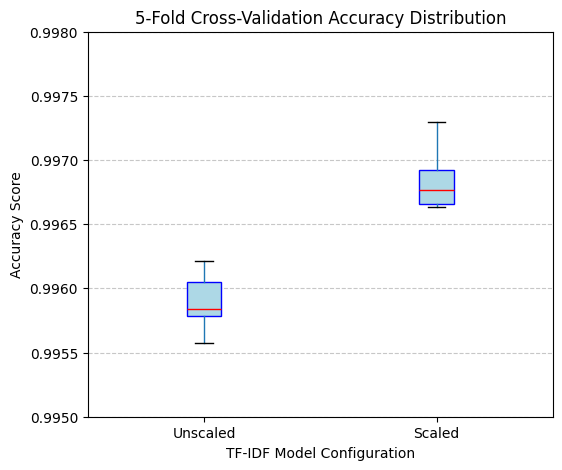

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd

plot_data = {
    'Unscaled': acc_lr_char_no_scale,
    'Scaled':   acc_lr_char
}

df_plot = pd.DataFrame(plot_data)

plt.figure(figsize=(6, 5))
# create boxplot
df_plot.boxplot(column=['Unscaled', 'Scaled'], grid=False, patch_artist=True,
           boxprops=dict(facecolor='lightblue', color='blue'),
           medianprops=dict(color='red'))

plt.title('5-Fold Cross-Validation Accuracy Distribution')
plt.ylabel('Accuracy Score')
plt.xlabel('TF-IDF Model Configuration')
plt.ylim(0.9950, 0.9980) # Zoom in to see the gap
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.savefig('kfold_boxplot.png', dpi=300)
plt.show()

In [ ]:
# Random Forest on TF-IDF character n-grams
vectorizer_char_rf = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)

pipe_rf_char = Pipeline([('tfidf', vectorizer_char_rf), ('rf', RandomForestClassifier(n_estimators=100))])
pipe_rf_char.fit(X_train_url, y_train_url)
print("Accuracy (Char-level, RF):", pipe_rf_char.score(X_test_url, y_test_url))

evaluate_model(pipe_rf_char, X_test_url, y_test_url)
best_rf_char, acc_rf_char = run_kfold_cv(X_train_url, y_train_url, pipe_rf_char)

Accuracy (Char-level, RF): 0.9978158994041434
Accuracy:  0.9978
Precision: 0.9998
Recall:    0.9951
F1 Score:  0.9974
------------------------------
Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99756 | Prec = 0.99938 | Rec = 0.99494 | F1 = 0.99715
Fold 2: Acc = 0.99674 | Prec = 0.99900 | Rec = 0.99336 | F1 = 0.99618
Fold 3: Acc = 0.99732 | Prec = 0.99938 | Rec = 0.99437 | F1 = 0.99687
Fold 4: Acc = 0.99687 | Prec = 0.99938 | Rec = 0.99331 | F1 = 0.99633
Fold 5: Acc = 0.99732 | Prec = 0.99907 | Rec = 0.99469 | F1 = 0.99688
--------------------------------------------------
Average Accuracy:  0.99716
Average Precision: 0.99924
Average Recall:    0.99413
Average F1-Score:  0.99668
Best Validation Accuracy: 0.99756


In [ ]:
# XGBoost on TF-IDF character n-grams

vectorizer_char_xgb = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), min_df=0.0001)

pipe_xgb_char = Pipeline([('tfidf', vectorizer_char_xgb), ('xgb', XGBClassifier(n_estimators=100, max_depth=6))])
pipe_xgb_char.fit(X_train_url, y_train_url)
print("Accuracy (Char-level, XGBoost):", pipe_xgb_char.score(X_test_url, y_test_url))

evaluate_model(pipe_xgb_char, X_test_url, y_test_url)
best_xgb_char, acc_xgb_char = run_kfold_cv(X_train_url, y_train_url, pipe_xgb_char)

Accuracy (Char-level, XGBoost): 0.9976038508026039
Accuracy:  0.9976
Precision: 0.9999
Recall:    0.9945
F1 Score:  0.9972
------------------------------
Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99775 | Prec = 0.99969 | Rec = 0.99506 | F1 = 0.99737
Fold 2: Acc = 0.99703 | Prec = 0.99950 | Rec = 0.99355 | F1 = 0.99652
Fold 3: Acc = 0.99738 | Prec = 0.99975 | Rec = 0.99412 | F1 = 0.99693
Fold 4: Acc = 0.99693 | Prec = 0.99981 | Rec = 0.99300 | F1 = 0.99639
Fold 5: Acc = 0.99732 | Prec = 0.99963 | Rec = 0.99414 | F1 = 0.99687
--------------------------------------------------
Average Accuracy:  0.99728
Average Precision: 0.99968
Average Recall:    0.99397
Average F1-Score:  0.99682
Best Validation Accuracy: 0.99775


In [ ]:
# evaluate on cleaned PhishOFE

print("\nEvaluating Unscaled Model on Cleaned Data...")
evaluate_model(pipe_char_no_scale, X_phishofe_clean, y_phishofe_clean)

print("\nEvaluating Scaled Model on Cleaned Data...")
evaluate_model(pipe_char, X_phishofe_clean, y_phishofe_clean)

print("\nEvaluating XGBoost (TF-IDF) on Cleaned PhishOFE Data...")
evaluate_model(pipe_xgb_char, X_phishofe_clean, y_phishofe_clean)


Evaluating Unscaled Model on Cleaned Data...
Accuracy:  0.9969
Precision: 0.9997
Recall:    0.9941
F1 Score:  0.9969
------------------------------

Evaluating Scaled Model on Cleaned Data...
Accuracy:  0.9963
Precision: 0.9978
Recall:    0.9949
F1 Score:  0.9964
------------------------------

Evaluating XGBoost (TF-IDF) on Cleaned PhishOFE Data...
Accuracy:  0.9980
Precision: 0.9993
Recall:    0.9968
F1 Score:  0.9981
------------------------------


**Cross dataset validation**

Cross dataset validation on PhishOFE for URL only features (excluding irreproducible features)

In [ ]:
not_computable_features_to_drop = [
    'URLSimilarityIndex',
    'URLTitleMatchScore',
    'DomainTitleMatchScore'
]

MODEL_FEATURES = [c for c in FEATURE_ORDER if c not in ('Domain', 'TLD')]
assert len(MODEL_FEATURES) == 21, MODEL_FEATURES
assert not (set(MODEL_FEATURES) & set(not_computable_features_to_drop))

missing = [c for c in MODEL_FEATURES if c not in data.columns]
assert not missing, f'absent from PhiUSIIL: {missing}'

has_scheme = phishofe_data_clean['URL'].astype(str).str.contains('://').mean()
print(f'PhishOFE URLs with an explicit scheme: {has_scheme:.1%}')   # want ~100%
if has_scheme < 0.99:
    print('  WARNING: scheme-less URLs read ~7-8 chars shorter and score IsHTTPS = 0.')

y_ext_url = phishofe_data_clean['label']
X_ext_url = extract_url_features_batch(phishofe_data_clean['URL'], chop=True)[MODEL_FEATURES]

y_ph = data['label']
X_ph = data[MODEL_FEATURES]

# test size = 0.2
test_size_requested = 0.2
X_train_ph, X_test_ph, y_train_ph, y_test_ph = train_test_split(
    X_ph, y_ph, test_size=test_size_requested, random_state=35)

assert list(X_train_ph.columns) == list(X_ext_url.columns)

"""logistic regression on reproduced URL features"""

lr_ph_pipe = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=2000))])

lr_ph_pipe.fit(X_train_ph, y_train_ph)
print("accuracy score = ", lr_ph_pipe.score(X_test_ph, y_test_ph))

print("LR - PhiUSIIL held-out")
evaluate_model(lr_ph_pipe, X_test_ph, y_test_ph)
print("LR - PhishOFE external")
evaluate_model(lr_ph_pipe, X_ext_url, y_ext_url)

best_lr_ph, acc_lr_ph = run_kfold_cv(X_train_ph, y_train_ph, lr_ph_pipe)

"""random forest on reproduced URL features"""

rf_ph_pipe = Pipeline([('rf', RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=35))])

rf_ph_pipe.fit(X_train_ph, y_train_ph)
print("accuracy score = ", rf_ph_pipe.score(X_test_ph, y_test_ph))

print("RF - PhiUSIIL held-out")
evaluate_model(rf_ph_pipe, X_test_ph, y_test_ph)
print("RF - PhishOFE external")
evaluate_model(rf_ph_pipe, X_ext_url, y_ext_url)

best_rf_ph, acc_rf_ph = run_kfold_cv(X_train_ph, y_train_ph, rf_ph_pipe)

"""XGBoost on reproduced URL features"""

xgb_ph_pipe = Pipeline([('xgb', XGBClassifier(n_estimators=100, max_depth=6))])

xgb_ph_pipe.fit(X_train_ph, y_train_ph)
print("accuracy score = ", xgb_ph_pipe.score(X_test_ph, y_test_ph))

print("XGBoost - PhiUSIIL held-out")
evaluate_model(xgb_ph_pipe, X_test_ph, y_test_ph)
print("XGBoost - PhishOFE external")
evaluate_model(xgb_ph_pipe, X_ext_url, y_ext_url)

best_xgb_ph, acc_xgb_ph = run_kfold_cv(X_train_ph, y_train_ph, xgb_ph_pipe)

PhishOFE URLs with an explicit scheme: 100.0%
accuracy score =  0.996352764053521
LR - PhiUSIIL held-out
Accuracy:  0.9964
Precision: 0.9996
Recall:    0.9918
F1 Score:  0.9957
------------------------------
LR - PhishOFE external
Accuracy:  0.9978
Precision: 0.9984
Recall:    0.9972
F1 Score:  0.9978
------------------------------
Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99616 | Prec = 0.99969 | Rec = 0.99136 | F1 = 0.99551
Fold 2: Acc = 0.99600 | Prec = 0.99950 | Rec = 0.99113 | F1 = 0.99530
Fold 3: Acc = 0.99608 | Prec = 0.99944 | Rec = 0.99140 | F1 = 0.99540
Fold 4: Acc = 0.99560 | Prec = 0.99937 | Rec = 0.99033 | F1 = 0.99483
Fold 5: Acc = 0.99647 | Prec = 0.99950 | Rec = 0.99228 | F1 = 0.99588
--------------------------------------------------
Average Accuracy:  0.99606
Average Precision: 0.99950
Average Recall:    0.99130
Average F1-Score:  0.99538
Best Validation Accuracy: 0.99647
accuracy score =  0.9966920418159843
RF - PhiUSIIL held-out
Accuracy:  0.9967
Precision

In [ ]:
# trivial baseline: does the URL start with https://www.?

base_te  = (data['URL'].astype(str).str.startswith('https://www.')).astype(int).loc[X_test_ph.index]
base_ext = (phishofe_data_clean['URL'].astype(str).str.startswith('https://www.')).astype(int)

print("Trivial baseline - PhiUSIIL held-out")
print(f"Accuracy:  {accuracy_score(y_test_ph, base_te):.4f}")
print(f"F1 Score:  {f1_score(y_test_ph, base_te):.4f}")
print("Trivial baseline - PhishOFE external")
print(f"Accuracy:  {accuracy_score(y_ext_url, base_ext):.4f}")
print(f"F1 Score:  {f1_score(y_ext_url, base_ext):.4f}")

Trivial baseline - PhiUSIIL held-out
Accuracy:  0.0101
F1 Score:  0.0199
Trivial baseline - PhishOFE external
Accuracy:  0.0127
F1 Score:  0.0251


In [ ]:
# does PhiUSIIL share PhishOFE's "www." collection artifact?

y_full = data['label']

print("PhiUSIIL — IsHTTPS vs label")
print(pd.crosstab(data['IsHTTPS'], data['label']))

print("\nPhiUSIIL — NoOfSubDomain vs label")
print(pd.crosstab(data['NoOfSubDomain'], data['label']))

starts_www = data['URL'].astype(str).str.startswith('https://www.')
print("\nPhiUSIIL — https://www. prefix vs label")
print(pd.crosstab(starts_www, data['label']))

pred_https = (data['IsHTTPS'] == 0).astype(int)
pred_subdomain = (data['NoOfSubDomain'] == 0).astype(int)
pred_www = (~starts_www).astype(int)

print(f"\nIsHTTPS-only baseline        acc={accuracy_score(y_full, pred_https):.4f}  f1={f1_score(y_full, pred_https):.4f}")
print(f"NoOfSubDomain==0 baseline    acc={accuracy_score(y_full, pred_subdomain):.4f}  f1={f1_score(y_full, pred_subdomain):.4f}")
print(f"https://www. baseline        acc={accuracy_score(y_full, pred_www):.4f}  f1={f1_score(y_full, pred_www):.4f}")

PhiUSIIL — IsHTTPS vs label
label         0      1
IsHTTPS               
0             0  51256
1        134850  49689

PhiUSIIL — NoOfSubDomain vs label
label               0      1
NoOfSubDomain               
0                   0  13983
1              114861  63545
2               18238  18115
3                1691   3428
4                  60   1503
5                   0    336
6                   0     21
7                   0      5
8                   0      4
10                  0      5

PhiUSIIL — https://www. prefix vs label
label       0      1
URL                 
False       0  98496
True   134850   2449

IsHTTPS-only baseline        acc=0.7893  f1=0.6735
NoOfSubDomain==0 baseline    acc=0.6312  f1=0.2433
https://www. baseline        acc=0.9896  f1=0.9877


In [ ]:
# drop the features implicated in the www./subdomain artifact and see how much PhishOFE generalization survives without them

ablation_features_to_drop = ['NoOfSubDomain', 'IsHTTPS']
MODEL_FEATURES_ABLATED = [c for c in MODEL_FEATURES if c not in ablation_features_to_drop]
assert len(MODEL_FEATURES_ABLATED) == len(MODEL_FEATURES) - len(ablation_features_to_drop)

X_train_ph_abl = X_train_ph[MODEL_FEATURES_ABLATED]
X_test_ph_abl  = X_test_ph[MODEL_FEATURES_ABLATED]
X_ext_url_abl  = X_ext_url[MODEL_FEATURES_ABLATED]

assert list(X_train_ph_abl.columns) == list(X_ext_url_abl.columns)

"""logistic regression, ablated"""
lr_ph_pipe_abl = Pipeline([('scaler', StandardScaler()), ('clf', LogisticRegression(max_iter=2000))])
lr_ph_pipe_abl.fit(X_train_ph_abl, y_train_ph)

print("LR (ablated: no NoOfSubDomain/IsHTTPS) - PhiUSIIL held-out")
evaluate_model(lr_ph_pipe_abl, X_test_ph_abl, y_test_ph)
print("LR (ablated) - PhishOFE external")
evaluate_model(lr_ph_pipe_abl, X_ext_url_abl, y_ext_url)

"""random forest, ablated"""
rf_ph_pipe_abl = Pipeline([('rf', RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=35))])
rf_ph_pipe_abl.fit(X_train_ph_abl, y_train_ph)

print("\nRF (ablated: no NoOfSubDomain/IsHTTPS) - PhiUSIIL held-out")
evaluate_model(rf_ph_pipe_abl, X_test_ph_abl, y_test_ph)
print("RF (ablated) - PhishOFE external")
evaluate_model(rf_ph_pipe_abl, X_ext_url_abl, y_ext_url)

LR (ablated: no NoOfSubDomain/IsHTTPS) - PhiUSIIL held-out
Accuracy:  0.9852
Precision: 0.9976
Recall:    0.9675
F1 Score:  0.9823
------------------------------
LR (ablated) - PhishOFE external
Accuracy:  0.9970
Precision: 0.9966
Recall:    0.9975
F1 Score:  0.9971
------------------------------

RF (ablated: no NoOfSubDomain/IsHTTPS) - PhiUSIIL held-out
Accuracy:  0.9952
Precision: 0.9943
Recall:    0.9945
F1 Score:  0.9944
------------------------------
RF (ablated) - PhishOFE external
Accuracy:  0.9952
Precision: 0.9921
Recall:    0.9986
F1 Score:  0.9953
------------------------------


In [ ]:
# separate check: evaluate the PhiUSIIL-trained reproduced-feature models
# (lr_ph_pipe, rf_ph_pipe from the cross-dataset validation cell above)
# against Feng & Yue (Colorado School of Mines, SACMAT 2020)

import dill, requests

FENG_YUE_URL = 'https://www.dropbox.com/scl/fi/gs6qqw2rovclnkhsdqslt/vonDataset20180426.dill?rlkey=s262zhfhottvxmdl41tz969g9&dl=1'
BROWSER_HEADERS = {
    'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 '
                  '(KHTML, like Gecko) Chrome/124.0 Safari/537.36'
}

resp = requests.get(FENG_YUE_URL, headers=BROWSER_HEADERS, stream=True, timeout=180)
resp.raise_for_status()
with open('vonDataset.dill', 'wb') as f:
    for chunk in resp.iter_content(chunk_size=1 << 20):
        f.write(chunk)

with open('vonDataset.dill', 'rb') as f:
    von_data = dill.load(f)

int_to_char = {v: k for k, v in von_data['char_to_int'].items()}

def decode_full(row):
    return ''.join(int_to_char.get(i, '') for i in row if i != 0)

X_von = np.concatenate([von_data['train_x'], von_data['val_x'], von_data['test_x']], axis=0)
y_von = np.concatenate([von_data['train_y'], von_data['val_y'], von_data['test_y']], axis=0)

feng_yue_urls = pd.Series([decode_full(row) for row in X_von])
y_feng_yue = pd.Series(y_von)

has_scheme_fy = feng_yue_urls.str.contains('://').mean()
print(f'Feng & Yue URLs with an explicit scheme: {has_scheme_fy:.1%}')

pct_truncated = feng_yue_urls.str.len().eq(150).mean()
print(f'Feng & Yue URLs at the 150-char encoding limit (likely truncated): {pct_truncated:.1%}')

X_feng_yue = extract_url_features_batch(feng_yue_urls, chop=True)[MODEL_FEATURES]

assert list(X_feng_yue.columns) == list(X_train_ph.columns)
print(f'X_feng_yue {X_feng_yue.shape}')

print("\nLR (trained on PhiUSIIL) - Feng & Yue external")
evaluate_model(lr_ph_pipe, X_feng_yue, y_feng_yue)

print("RF (trained on PhiUSIIL) - Feng & Yue external")
evaluate_model(rf_ph_pipe, X_feng_yue, y_feng_yue)

print("XGBoost (trained on PhiUSIIL) - Feng & Yue external")
evaluate_model(xgb_ph_pipe, X_feng_yue, y_feng_yue)

Feng & Yue URLs with an explicit scheme: 100.0%
Feng & Yue URLs at the 150-char encoding limit (likely truncated): 9.4%
X_feng_yue (1559362, 21)

LR (trained on PhiUSIIL) - Feng & Yue external
Accuracy:  0.4894
Precision: 0.4882
Recall:    0.9997
F1 Score:  0.6560
------------------------------
RF (trained on PhiUSIIL) - Feng & Yue external
Accuracy:  0.4883
Precision: 0.4876
Recall:    0.9999
F1 Score:  0.6555
------------------------------
XGBoost (trained on PhiUSIIL) - Feng & Yue external
Accuracy:  0.4890
Precision: 0.4879
Recall:    0.9999
F1 Score:  0.6558
------------------------------


**End cross dataset validation**

Dataset including derived and webpage scores (excluding URL Similarity Index)

In [ ]:
columns_to_drop_web = ['label', 'URL', 'Domain', 'TLD', 'Title', 'URLSimilarityIndex']

y_all = data['label']
X_all = data.drop(columns=columns_to_drop_web)

# test size = 0.2
test_size_requested = 0.2
X_train_all, X_test_all, y_train_all, y_test_all = train_test_split(X_all, y_all, test_size=test_size_requested, random_state=35)

Logistic regression including derived and webpage Scores (excluding URL Similarity Index)



In [ ]:
# logistic regression

# max_iter=5000
lr_all = LogisticRegression(max_iter=5000)

lr_all_pipe = Pipeline([('scaler', StandardScaler()), ('lr', lr_all)])
lr_all_pipe.fit(X_train_all, y_train_all)
y_all_pred_lr = lr_all_pipe.predict(X_test_all)

print("accuracy score = ", lr_all_pipe.score(X_test_all, y_test_all))

evaluate_model(lr_all_pipe, X_test_all, y_test_all)

accuracy score =  0.999215420174304
Accuracy:  0.9992
Precision: 0.9994
Recall:    0.9988
F1 Score:  0.9991
------------------------------


In [ ]:
run_kfold_cv(X_train_all, y_train_all, lr_all_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99923 | Prec = 0.99969 | Rec = 0.99852 | F1 = 0.99910
Fold 2: Acc = 0.99902 | Prec = 0.99888 | Rec = 0.99882 | F1 = 0.99885
Fold 3: Acc = 0.99939 | Prec = 0.99957 | Rec = 0.99901 | F1 = 0.99929
Fold 4: Acc = 0.99936 | Prec = 0.99938 | Rec = 0.99913 | F1 = 0.99926
Fold 5: Acc = 0.99934 | Prec = 0.99957 | Rec = 0.99889 | F1 = 0.99923
--------------------------------------------------
Average Accuracy:  0.99927
Average Precision: 0.99942
Average Recall:    0.99887
Average F1-Score:  0.99915
Best Validation Accuracy: 0.99939


(Pipeline(steps=[('scaler', StandardScaler()),
                 ('lr', LogisticRegression(max_iter=5000))]),
 [0.9992313401187447,
  0.9990192700188194,
  0.9993903570387256,
  0.999363850823018,
  0.9993373446073104])

In [ ]:
# random forest

# n=100
rf_all = RandomForestClassifier(n_estimators=100)

rf_all_pipe = Pipeline([('rf', rf_all)])
rf_all_pipe.fit(X_train_all, y_train_all)
y_all_pred_rf = rf_all_pipe.predict(X_test_all)

accuracy = accuracy_score(y_test_all, y_all_pred_rf)

print("accuracy score = ", accuracy)

evaluate_model(rf_all_pipe, X_test_all, y_test_all)

accuracy score =  0.9997879513984606
Accuracy:  0.9998
Precision: 1.0000
Recall:    0.9995
F1 Score:  0.9998
------------------------------


In [ ]:
best_rf_all, acc_rf_all = run_kfold_cv(X_train_all, y_train_all, rf_all_pipe)

Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99989 | Prec = 0.99988 | Rec = 0.99988 | F1 = 0.99988
Fold 2: Acc = 0.99992 | Prec = 0.99988 | Rec = 0.99994 | F1 = 0.99991
Fold 3: Acc = 0.99995 | Prec = 1.00000 | Rec = 0.99988 | F1 = 0.99994
Fold 4: Acc = 0.99981 | Prec = 1.00000 | Rec = 0.99957 | F1 = 0.99978
Fold 5: Acc = 0.99987 | Prec = 0.99994 | Rec = 0.99975 | F1 = 0.99985
--------------------------------------------------
Average Accuracy:  0.99989
Average Precision: 0.99994
Average Recall:    0.99980
Average F1-Score:  0.99987
Best Validation Accuracy: 0.99995


In [ ]:
# wilconox test between RF (W/ webpage scores) and LR (W/ derived and webpage scores)

compare_models_wilcoxon(
    acc_rf_web,
    acc_rf_all,
    model_a_name="RF (URL + HTML)",
    model_b_name="RF (All Features)"
)


--- Wilcoxon Signed-Rank Test: RF (URL + HTML) vs RF (All Features) ---
Wilcoxon Statistic: 2.5000
P-value: 0.25000
Rank-biserial effect size r = 0.750  (n=4 non-tied paired folds)
Result: NO statistically significant difference (Fail to reject H0).
Conclusion: The performance difference is likely due to random chance.


In [ ]:
# XGBoost on All Features

xgb_all = XGBClassifier(n_estimators=100, max_depth=6)

xgb_all_pipe = Pipeline([('xgb', xgb_all)])
xgb_all_pipe.fit(X_train_all, y_train_all)
y_all_pred_xgb = xgb_all_pipe.predict(X_test_all)

accuracy = accuracy_score(y_test_all, y_all_pred_xgb)

print("accuracy score = ", accuracy)

evaluate_model(xgb_all_pipe, X_test_all, y_test_all)

best_xgb_all, acc_xgb_all = run_kfold_cv(X_train_all, y_train_all, xgb_all_pipe)

accuracy score =  0.9999363854195381
Accuracy:  0.9999
Precision: 1.0000
Recall:    0.9999
F1 Score:  0.9999
------------------------------
Starting 5-Fold Cross Validation...
Fold 1: Acc = 0.99995 | Prec = 1.00000 | Rec = 0.99988 | F1 = 0.99994
Fold 2: Acc = 0.99995 | Prec = 0.99988 | Rec = 1.00000 | F1 = 0.99994
Fold 3: Acc = 0.99995 | Prec = 1.00000 | Rec = 0.99988 | F1 = 0.99994
Fold 4: Acc = 0.99989 | Prec = 1.00000 | Rec = 0.99975 | F1 = 0.99988
Fold 5: Acc = 0.99984 | Prec = 0.99988 | Rec = 0.99975 | F1 = 0.99981
--------------------------------------------------
Average Accuracy:  0.99992
Average Precision: 0.99995
Average Recall:    0.99985
Average F1-Score:  0.99990
Best Validation Accuracy: 0.99995


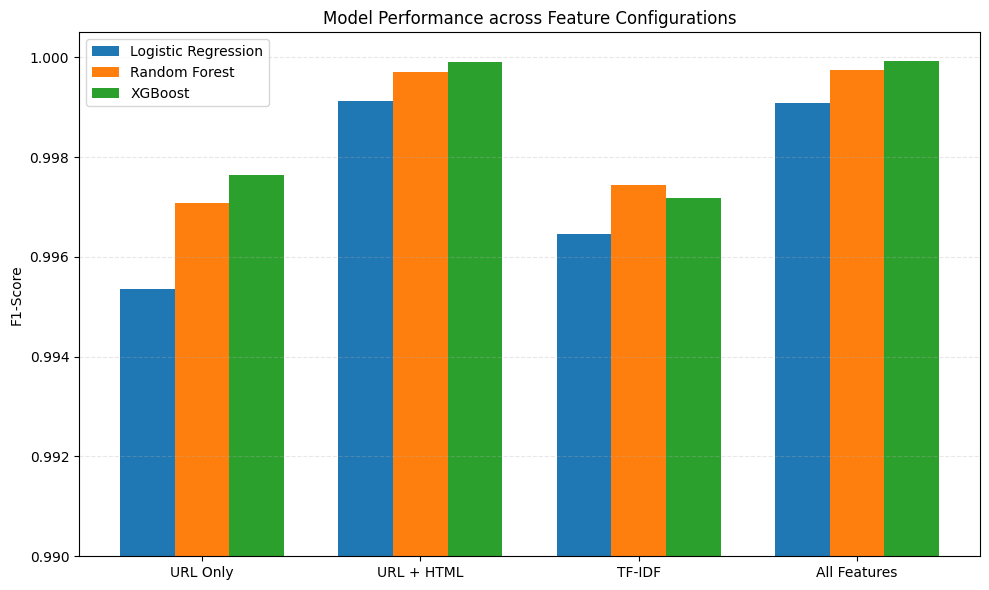

In [ ]:
# plot all results in a bar graph

configs = ['URL Only', 'URL + HTML', 'TF-IDF', 'All Features']
lr_scores = [
    f1_score(y_test_num, lr_pipe.predict(X_test_num)),
    f1_score(y_test_web, lr_web_pipe.predict(X_test_web)),
    f1_score(y_test_url, pipe_char.predict(X_test_url)),
    f1_score(y_test_all, lr_all_pipe.predict(X_test_all)),
]

rf_scores = [
    f1_score(y_test_num, rf_pipe.predict(X_test_num)),
    f1_score(y_test_web, rf_web_pipe.predict(X_test_web)),
    f1_score(y_test_url, pipe_rf_char.predict(X_test_url)),
    f1_score(y_test_all, rf_all_pipe.predict(X_test_all)),
]

xgb_scores = [
    f1_score(y_test_num, xgb_pipe.predict(X_test_num)),
    f1_score(y_test_web, xgb_web_pipe.predict(X_test_web)),
    f1_score(y_test_url, pipe_xgb_char.predict(X_test_url)),
    f1_score(y_test_all, xgb_all_pipe.predict(X_test_all)),
]

models = [
    {'name': 'Logistic Regression', 'scores': lr_scores, 'color': '#1f77b4'},
    {'name': 'Random Forest', 'scores': rf_scores, 'color': '#ff7f0e'},
    {'name': 'XGBoost', 'scores': xgb_scores, 'color': '#2ca02c'}
]

x = np.arange(len(configs))
width = 0.25

fig, ax = plt.subplots(figsize=(10, 6))

added_labels = set()

for i in x:
    valid_bars = []
    for model in models:
        score = model['scores'][i]
        if score > 0:
            valid_bars.append({'score': score, 'color': model['color'], 'name': model['name']})

    n_bars = len(valid_bars)
    if n_bars == 0:
        continue

    # offset to center bars

    for j, bar_data in enumerate(valid_bars):
        offset = (j - (n_bars - 1) / 2) * width

        label = bar_data['name'] if bar_data['name'] not in added_labels else None
        if label:
            added_labels.add(label)

        ax.bar(i + offset, bar_data['score'], width, label=label, color=bar_data['color'])

ax.set_ylabel('F1-Score')
ax.set_title('Model Performance across Feature Configurations')
ax.set_xticks(x)
ax.set_xticklabels(configs)
ax.set_ylim(0.99, 1.0005)
ax.legend(loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.savefig('model_comparison_centered.png', dpi=300)
plt.show()

Qualitative Analysis of RF (URL + HTML)

In [ ]:
def get_false_negatives(model, X_test, y_test, original_data, model_name="Model"):
    """
    Identifies False Negatives (Actual=1, Predicted=0) and retrieves
    the original URL and features for qualitative analysis.
    """
    # get predictions
    y_pred = model.predict(X_test)

    # convert y_test to series
    if not isinstance(y_test, pd.Series):
        y_test = pd.Series(y_test)

    # find indices where actual is 1 but predicted is 0
    fn_indices = y_test.index[(y_test == 1) & (y_pred == 0)]

    # retrieve the rows from the original dataset
    fn_data = original_data.loc[fn_indices]

    print(f"--- {model_name} ---")
    print(f"Total False Negatives: {len(fn_data)}")

    if len(fn_data) > 0:
        print("Sample False Negative URLs:")
        # display index and URL for easy lookup
        for idx, url in fn_data['URL'].head(5).items():
            print(f"Index {idx}: {url}")
        print("\n")
    else:
        print("Perfect recall (0 False Negatives).\n")

    return fn_data

In [ ]:
# random forest (url + html)

fn_data = get_false_negatives(rf_web_pipe, X_test_web, y_test_web, data, model_name="RF (W/ webpage scores)")

--- RF (W/ webpage scores) ---
Total False Negatives: 12
Sample False Negative URLs:
Index 76258: https://www.vmailmessage.com
Index 78962: https://www.tincanmonsters.com/
Index 112781: https://byil.blogspot.com/
Index 105405: https://www.interprocesoswebcancannovil.top/
Index 150614: https://pha.xujmno.xyz/logi/




In [ ]:
def get_true_positives(model, X_test, y_test, original_data, model_name="Model"):
    """
    Identifies True Positives (Actual=1, Predicted=1) and retrieves
    the original URL and features for qualitative analysis.
    """
    # get predictions
    y_pred = model.predict(X_test)

    # convert y_test to series
    if not isinstance(y_test, pd.Series):
        y_test = pd.Series(y_test)

    # find indices where actual is 1 and predicted is 1
    tp_indices = y_test.index[(y_test == 1) & (y_pred == 1)]

    # retrieve the rows from the original dataset
    tp_data = original_data.loc[tp_indices]

    print(f"--- {model_name} ---")
    print(f"Total True Positives: {len(tp_data)}")

    if len(tp_data) > 0:
        print("Sample True Positive URLs (Correctly Detected):")
        # display index and URL for easy lookup
        for idx, url in tp_data['URL'].head(5).items():
            print(f"Index {idx}: {url}")
        print("\n")
    else:
        print("No True Positives found (0 detected).\n")

    return tp_data

In [ ]:
# recall rate on HTTPS subset for RF (URL + HTML)

https_mask = X_test_web['IsHTTPS'] == 1

X_test_https = X_test_web[https_mask]
y_test_https = y_test_web[https_mask]

print(f"Total HTTPS websites in test set: {len(X_test_https)}")
print(f"Total HTTPS Phishing sites in test set: {y_test_https.sum()}") # 1=Phishing
print("-" * 30)

https_phishing_mask = y_test_https == 1
X_test_https_phishing = X_test_https[https_phishing_mask]
y_test_https_phishing = y_test_https[https_phishing_mask]

https_successes = get_true_positives(
    rf_web_pipe,
    X_test_https_phishing,
    y_test_https_phishing,
    data,
    model_name="RF (URL+HTML) - HTTPS Phishing Detection"
)

total_https_phish = len(y_test_https_phishing)
detected_https_phish = len(https_successes)

if total_https_phish > 0:
    recall_on_https = detected_https_phish / total_https_phish
    print(f"Summary: The model correctly identified {detected_https_phish} out of {total_https_phish} HTTPS phishing sites.")
    print(f"HTTPS Recall Rate: {recall_on_https:.2%}")
else:
    print("No HTTPS phishing sites found in the test set to analyze.")

Total HTTPS websites in test set: 36933
Total HTTPS Phishing sites in test set: 9893
------------------------------
--- RF (URL+HTML) - HTTPS Phishing Detection ---
Total True Positives: 9881
Sample True Positive URLs (Correctly Detected):
Index 102449: https://doncov.line.pm/
Index 111111: https://cloudflare-ipfs.com/ipfs/bafybeihxptow7hycar3aghbxd4xvws4sucyqh2tzgz3wvo7eoj4qkrgahy
Index 46152: https://szinv2.web.app/
Index 164597: https://heartfeltlightapplicationstack--promeriy.repl.co/
Index 176294: https://juriskiana11.firebaseapp.com/


Summary: The model correctly identified 9881 out of 9893 HTTPS phishing sites.
HTTPS Recall Rate: 99.88%


**Time sensitivity check for USI**

In [ ]:
import time

# faithful port of PhiUSIIL Algorithm 2 (Prasad & Chandra, 2024, p.8)

def _get_min(a, b):
    return (a, b, len(a)) if len(a) <= len(b) else (b, a, len(b))

def url_similarity_index(src, tar):
    X, Y, n = _get_min(src, tar)
    N = max(len(src), len(tar))
    if N == 0:
        return 0.0
    SI = 0.0
    a = 50.0 / N
    nsum = N * (N + 1) / 2
    i = 0
    while i < n:
        if X[i] == Y[i]:
            SI += a + (50.0 * (N - i)) / nsum
            i += 1
        else:
            Y = Y[:i] + Y[i + 1:]
            X, Y, n = _get_min(X, Y)
            # i does not advance: retry this position against the shrunk Y
    return SI

# batch-timed microbenchmark
def bench_batch(fn, args_list, reps=5):
    """Seconds/call, min over `reps` full passes -- amortizes Python call
    overhead and timer resolution, which dominate at microsecond scale."""
    times = []
    for _ in range(reps):
        t0 = time.perf_counter()
        for args in args_list:
            fn(*args)
        t1 = time.perf_counter()
        times.append((t1 - t0) / len(args_list))
    return min(times)

sample_urls = data['URL'].astype(str).sample(5000, random_state=35).tolist()

t_full = bench_batch(lambda u: extract_url_features(u), [(u,) for u in sample_urls])
print(f"All 21 URL-only features: {t_full*1e6:.1f} µs/URL")

def derived_only(url):
    domain = url.split('://', 1)[1].split('/')[0] if '://' in url else url.split('/')[0]
    tld = domain.split('.')[-1] if '.' in domain else ''
    return (
        _char_continuation_rate(_root_domain(domain)),
        _url_char_prob(url),
        TLD_LEGITIMATE_PROB.get(tld, 0.0),
    )

t_derived = bench_batch(derived_only, [(u,) for u in sample_urls])
print(f"Just the 3 cheap derived scores: {t_derived*1e6:.1f} µs/URL "
      f"({t_derived/t_full:.0%} of full extraction)")

targets = data['URL'].astype(str).sample(len(sample_urls), random_state=99).tolist()
t_pairwise = bench_batch(url_similarity_index, list(zip(sample_urls, targets)))
print(f"One pairwise USI comparison: {t_pairwise*1e6:.2f} µs")

# sensitivity table: credits the authors with the obvious optimization
# (57.5% of rows are exact matches, resolvable by O(1) hash lookup, no scan
# needed) and reports a range from naive to implausibly-optimized
usi100 = (data['URLSimilarityIndex'] == 100).mean()
print(f"\nExact USI=100 matches (O(1) hash lookup, no scan needed): {usi100:.1%}")

naive_cost = t_pairwise * 10_000_000  # full linear scan against the 10M list, per URL
rows = []
for speedup in [1, 36, 100, 1000, 10_000]:
    cost = naive_cost / speedup * (1 - usi100)
    rows.append({'implementation': f'{speedup}x speedup over naive scan',
                  'usi_cost_per_url_s': cost,
                  'vs_all_21_url_features_x': cost / t_full})

sensitivity_df = pd.DataFrame(rows)
print(sensitivity_df.to_string(index=False))

All 21 URL-only features: 15.4 µs/URL
Just the 3 cheap derived scores: 8.5 µs/URL (55% of full extraction)
One pairwise USI comparison: 13.62 µs

Exact USI=100 matches (O(1) hash lookup, no scan needed): 57.5%
                implementation  usi_cost_per_url_s  vs_all_21_url_features_x
    1x speedup over naive scan           57.856201              3.756753e+06
   36x speedup over naive scan            1.607117              1.043542e+05
  100x speedup over naive scan            0.578562              3.756753e+04
 1000x speedup over naive scan            0.057856              3.756753e+03
10000x speedup over naive scan            0.005786              3.756753e+02


**End time sensitivity check**

**Improve hypothesis testing**

In [ ]:
def bootstrap_paired_diff(y_true_a, pred_a, y_true_b, pred_b, metric=accuracy_score, n_boot=2000, random_state=35):
    """95% CI for the difference in `metric` (model_b - model_a) via paired
    bootstrap resampling of the shared test-set rows."""
    y_true_a, pred_a = np.asarray(y_true_a), np.asarray(pred_a)
    y_true_b, pred_b = np.asarray(y_true_b), np.asarray(pred_b)
    assert (y_true_a == y_true_b).all(), "rows are not aligned -- check the two splits share indices"
    n = len(y_true_a)
    rng = np.random.RandomState(random_state)
    diffs = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.randint(0, n, n)
        diffs[i] = metric(y_true_b[idx], pred_b[idx]) - metric(y_true_a[idx], pred_a[idx])
    ci_lo, ci_hi = np.percentile(diffs, [2.5, 97.5])
    p_le_zero = (diffs <= 0).mean()
    return diffs, (ci_lo, ci_hi), p_le_zero

# apply to the same three comparisons already in the notebook
_, ci, p = bootstrap_paired_diff(y_test_num, rf_pipe.predict(X_test_num),
                                   y_test_web, rf_web_pipe.predict(X_test_web))
print(f"RF URL+HTML minus RF URL Only — 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]  (P(diff<=0) = {p:.4f})")

_, ci, p = bootstrap_paired_diff(y_test_url, pipe_char_no_scale.predict(X_test_url),
                                   y_test_url, pipe_char.predict(X_test_url))
print(f"LR TF-IDF Scaled minus Unscaled — 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]  (P(diff<=0) = {p:.4f})")

_, ci, p = bootstrap_paired_diff(y_test_web, rf_web_pipe.predict(X_test_web),
                                   y_test_all, rf_all_pipe.predict(X_test_all))
print(f"RF All Features minus RF URL+HTML — 95% CI: [{ci[0]:.4f}, {ci[1]:.4f}]  (P(diff<=0) = {p:.4f})")

RF URL+HTML minus RF URL Only — 95% CI: [0.0018, 0.0027]  (P(diff<=0) = 0.0000)
LR TF-IDF Scaled minus Unscaled — 95% CI: [0.0003, 0.0012]  (P(diff<=0) = 0.0005)
RF All Features minus RF URL+HTML — 95% CI: [0.0000, 0.0001]  (P(diff<=0) = 0.1365)


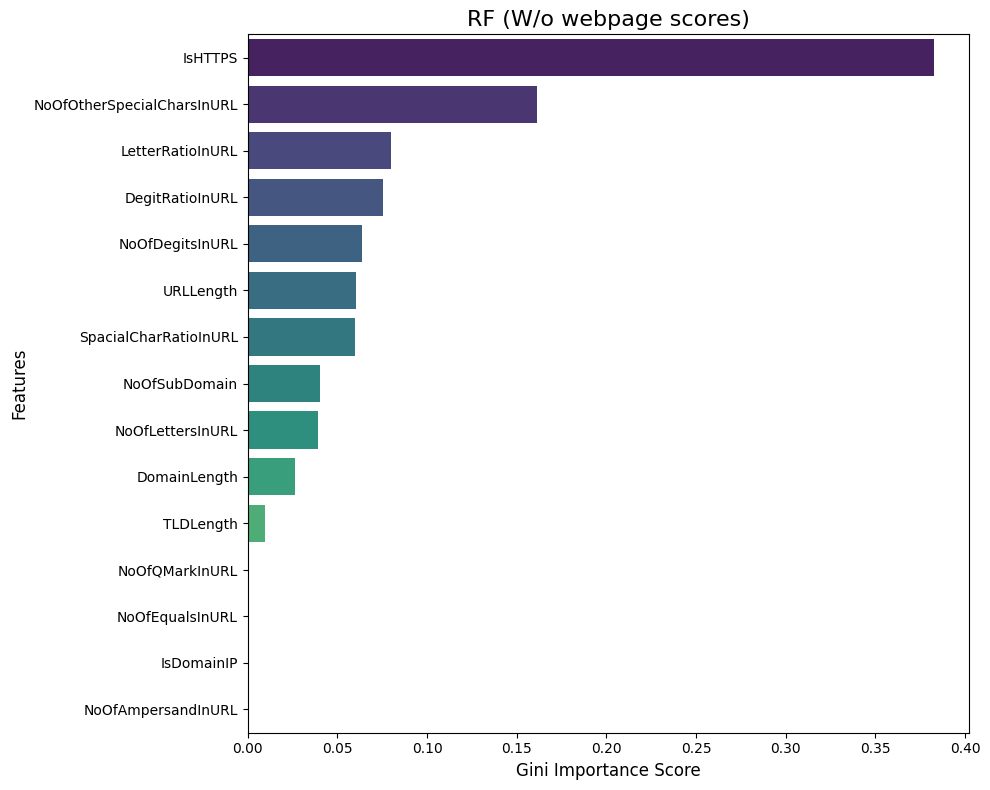

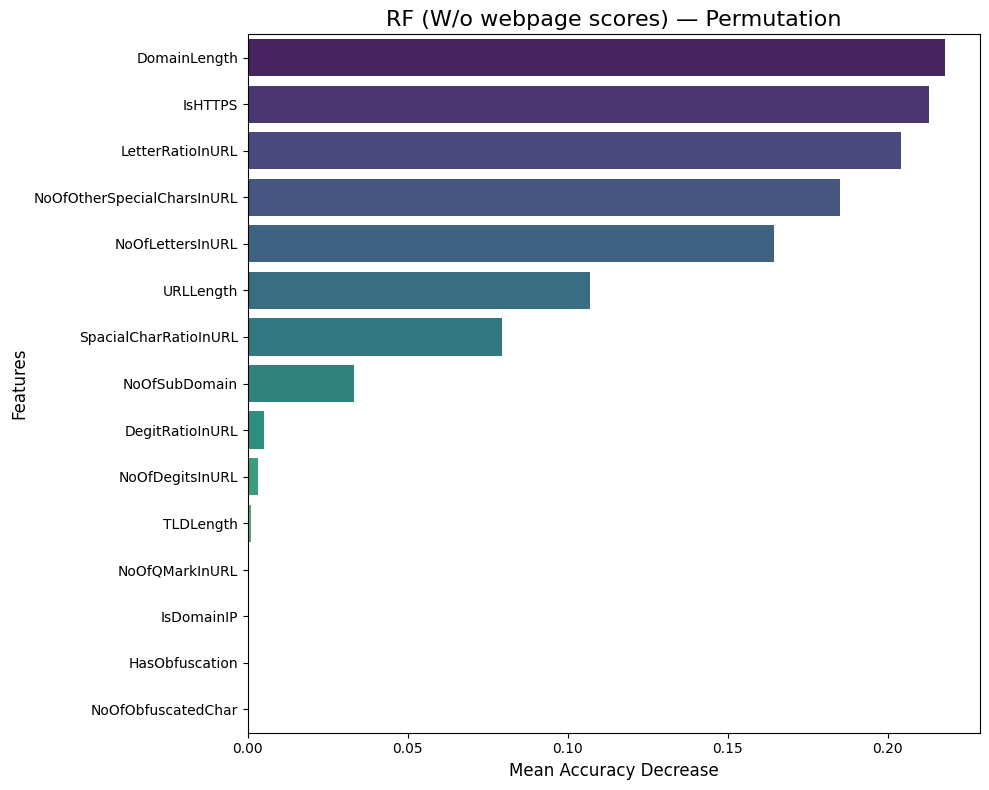

=== RF (URL Only) — Permutation Importance ===
                       Feature  Importance
1                 DomainLength    0.217937
17                     IsHTTPS    0.212818
9             LetterRatioInURL    0.204188
15  NoOfOtherSpecialCharsInURL    0.185114
8             NoOfLettersInURL    0.164516
0                    URLLength    0.106847
16       SpacialCharRatioInURL    0.079567
4                NoOfSubDomain    0.033287
11             DegitRatioInURL    0.004917
10             NoOfDegitsInURL    0.003094
3                    TLDLength    0.000901
13              NoOfQMarkInURL    0.000002
2                   IsDomainIP    0.000000
5               HasObfuscation    0.000000
6           NoOfObfuscatedChar    0.000000



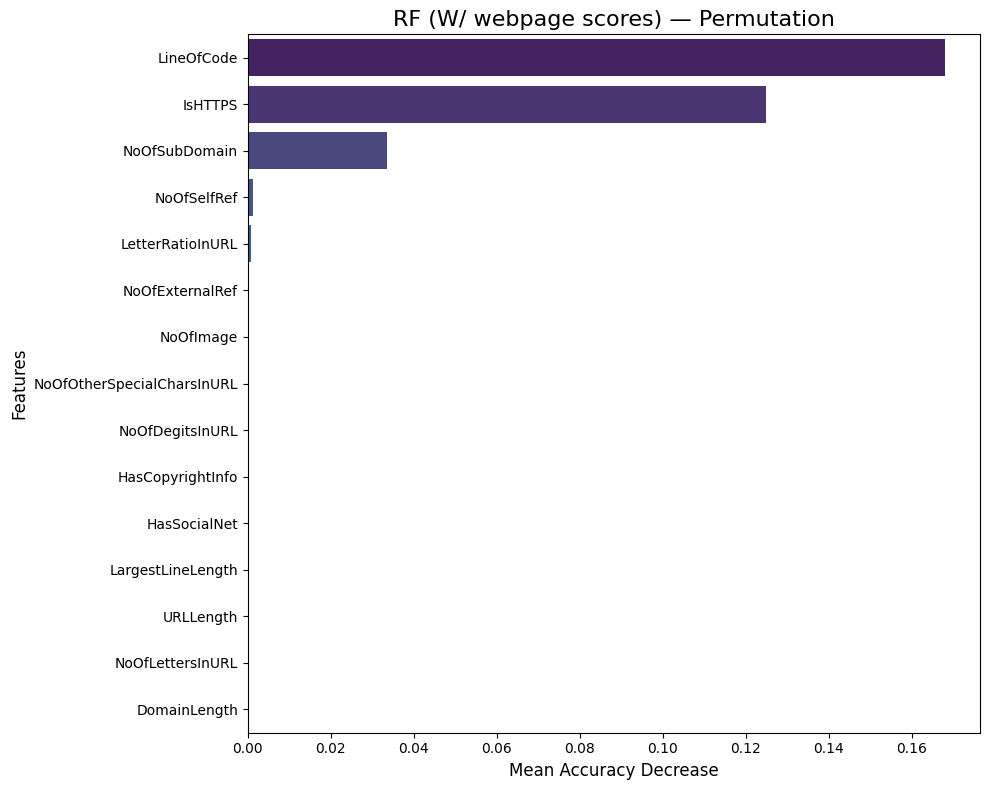

=== RF (URL + HTML) — Permutation Importance ===
                       Feature  Importance
18                  LineOfCode    0.167979
17                     IsHTTPS    0.124911
4                NoOfSubDomain    0.033616
41                 NoOfSelfRef    0.001171
9             LetterRatioInURL    0.000833
43             NoOfExternalRef    0.000297
38                   NoOfImage    0.000197
15  NoOfOtherSpecialCharsInURL    0.000182
10             NoOfDegitsInURL    0.000157
37            HasCopyrightInfo    0.000042
30                HasSocialNet    0.000023
19           LargestLineLength    0.000021
0                    URLLength    0.000017
8             NoOfLettersInURL    0.000015
1                 DomainLength    0.000008



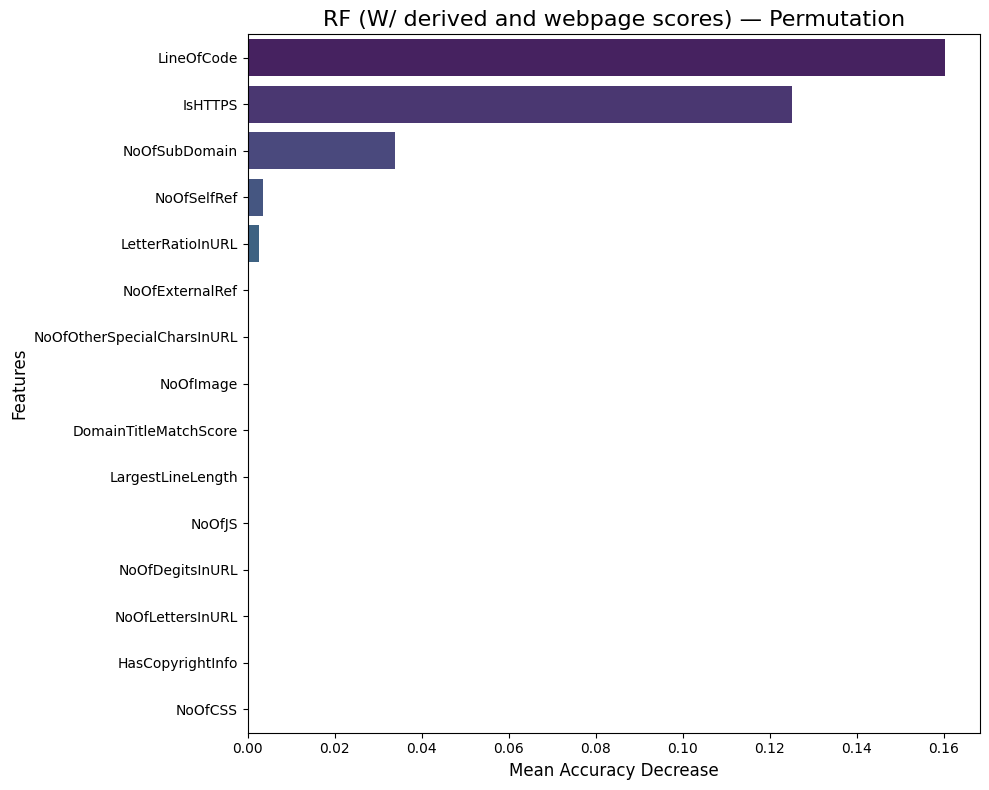

=== RF (All Features) — Permutation Importance ===
                       Feature  Importance
21                  LineOfCode    0.160285
20                     IsHTTPS    0.125081
7                NoOfSubDomain    0.033728
46                 NoOfSelfRef    0.003389
12            LetterRatioInURL    0.002576
48             NoOfExternalRef    0.000176
18  NoOfOtherSpecialCharsInURL    0.000144
43                   NoOfImage    0.000131
24       DomainTitleMatchScore    0.000070
22           LargestLineLength    0.000051
45                      NoOfJS    0.000047
13             NoOfDegitsInURL    0.000040
11            NoOfLettersInURL    0.000038
42            HasCopyrightInfo    0.000036
44                     NoOfCSS    0.000025



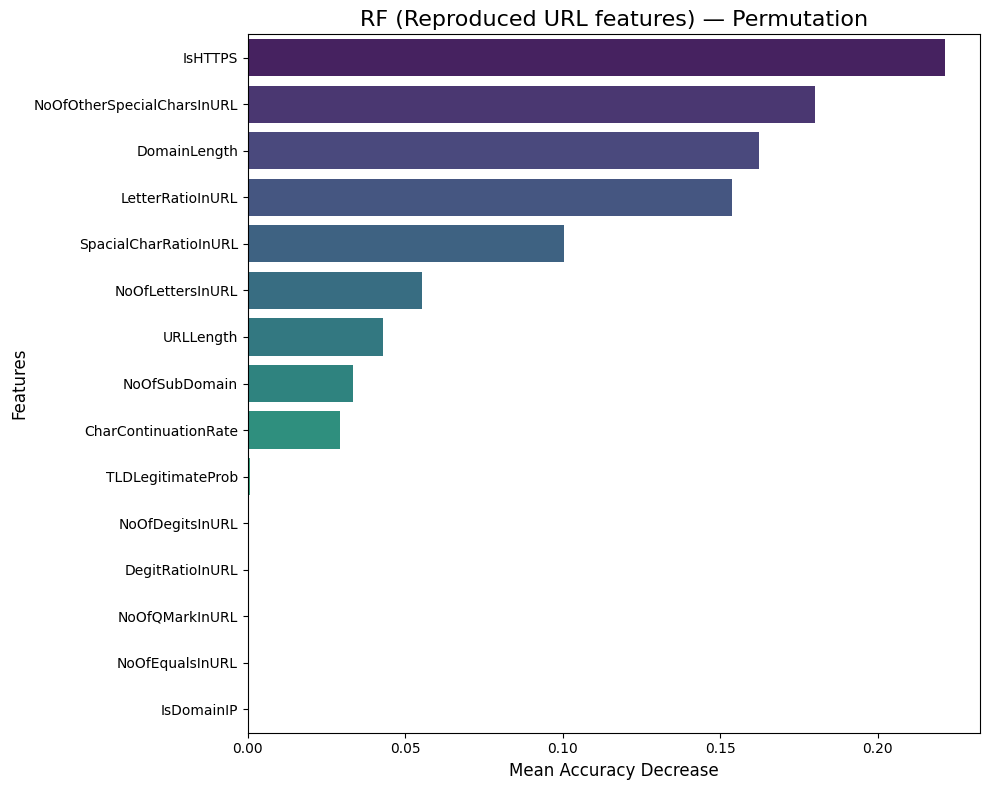

=== RF (Reproduced URL Features) — Permutation Importance ===
                       Feature  Importance
17                     IsHTTPS    0.221430
15  NoOfOtherSpecialCharsInURL    0.179976
0                 DomainLength    0.162349
9             LetterRatioInURL    0.153854
16       SpacialCharRatioInURL    0.100467
8             NoOfLettersInURL    0.055258
2                    URLLength    0.042849
4                NoOfSubDomain    0.033466
18        CharContinuationRate    0.029233
19           TLDLegitimateProb    0.000589
10             NoOfDegitsInURL    0.000454
11             DegitRatioInURL    0.000452
13              NoOfQMarkInURL    0.000004
12             NoOfEqualsInURL    0.000004
3                   IsDomainIP    0.000000



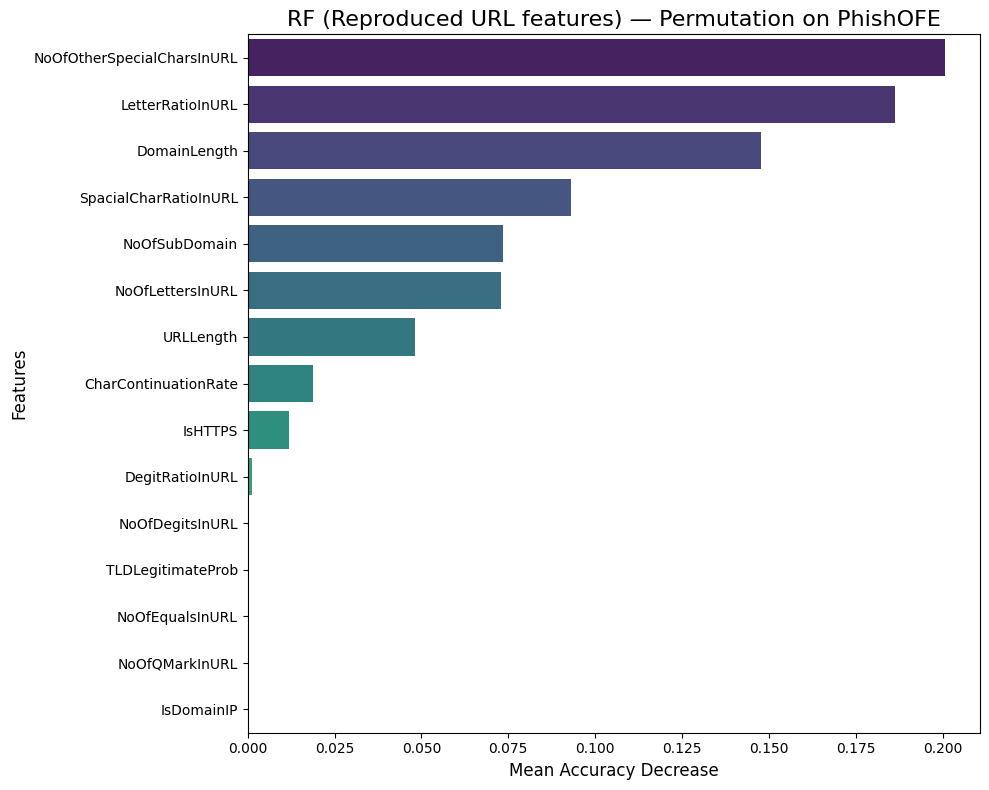

=== RF (Reproduced URL features) — Permutation on PhishOFE ===
                       Feature  Importance
15  NoOfOtherSpecialCharsInURL    0.200752
9             LetterRatioInURL    0.186356
0                 DomainLength    0.147821
16       SpacialCharRatioInURL    0.093023
4                NoOfSubDomain    0.073600
8             NoOfLettersInURL    0.073011
2                    URLLength    0.048229
18        CharContinuationRate    0.018729
17                     IsHTTPS    0.011834
11             DegitRatioInURL    0.001253
10             NoOfDegitsInURL    0.000374
19           TLDLegitimateProb    0.000051
12             NoOfEqualsInURL    0.000008
13              NoOfQMarkInURL    0.000004
3                   IsDomainIP    0.000000


In [ ]:
from sklearn.inspection import permutation_importance

def plot_permutation_importance(pipeline, X_test, y_test, top_n=15, title="Permutation Importance", n_repeats=10):
    result = permutation_importance(pipeline, X_test, y_test, n_repeats=n_repeats,
                                     random_state=35, scoring='accuracy', n_jobs=-1)
    feature_df = pd.DataFrame({
        'Feature': X_test.columns,
        'Importance': result.importances_mean
    }).sort_values(by='Importance', ascending=False).head(top_n)

    plt.figure(figsize=(10, 8))
    sns.barplot(x='Importance', y='Feature', hue='Feature', data=feature_df, palette='viridis', legend=False)
    plt.title(title, fontsize=16)
    plt.xlabel('Mean Accuracy Decrease', fontsize=12)
    plt.ylabel('Features', fontsize=12)
    plt.tight_layout()
    plt.show()
    return feature_df

plot_top_features(rf_pipe, X_train_num, title="RF (W/o webpage scores)")  # unchanged, for reference
imp_url = plot_permutation_importance(rf_pipe, X_test_num, y_test_num, title="RF (W/o webpage scores) — Permutation")

print("=== RF (URL Only) — Permutation Importance ===")
print(imp_url.to_string())
print()

imp_web = plot_permutation_importance(rf_web_pipe, X_test_web, y_test_web, title="RF (W/ webpage scores) — Permutation")

print("=== RF (URL + HTML) — Permutation Importance ===")
print(imp_web.to_string())
print()

imp_all = plot_permutation_importance(rf_all_pipe, X_test_all, y_test_all, title="RF (W/ derived and webpage scores) — Permutation")

print("=== RF (All Features) — Permutation Importance ===")
print(imp_all.to_string())
print()

imp_php = plot_permutation_importance(rf_ph_pipe, X_test_ph, y_test_ph, title="RF (Reproduced URL features) — Permutation")

print("=== RF (Reproduced URL Features) — Permutation Importance ===")
print(imp_php.to_string())
print()

imp_ph_ext = plot_permutation_importance(rf_ph_pipe, X_ext_url, y_ext_url, title="RF (Reproduced URL features) — Permutation on PhishOFE")
print("=== RF (Reproduced URL features) — Permutation on PhishOFE ===")
print(imp_ph_ext.to_string())

In [ ]:
# print all false negatives before SHAP analysis

print(fn_data['URL'])

76258                          https://www.vmailmessage.com
78962                       https://www.tincanmonsters.com/
112781                           https://byil.blogspot.com/
105405         https://www.interprocesoswebcancannovil.top/
150614                         https://pha.xujmno.xyz/logi/
63616                         https://www.alshayagropu.com/
30066                       https://www.connextsbridge.com/
95625                              https://www.seedjfly.top
58437                     https://www.pencakefistaking.com/
42062                              https://binarypiano.com/
28452                       https://rariblies.blogspot.com/
63877     https://www.foroarte.es/wp/privacy-policy/logi...
Name: URL, dtype: object


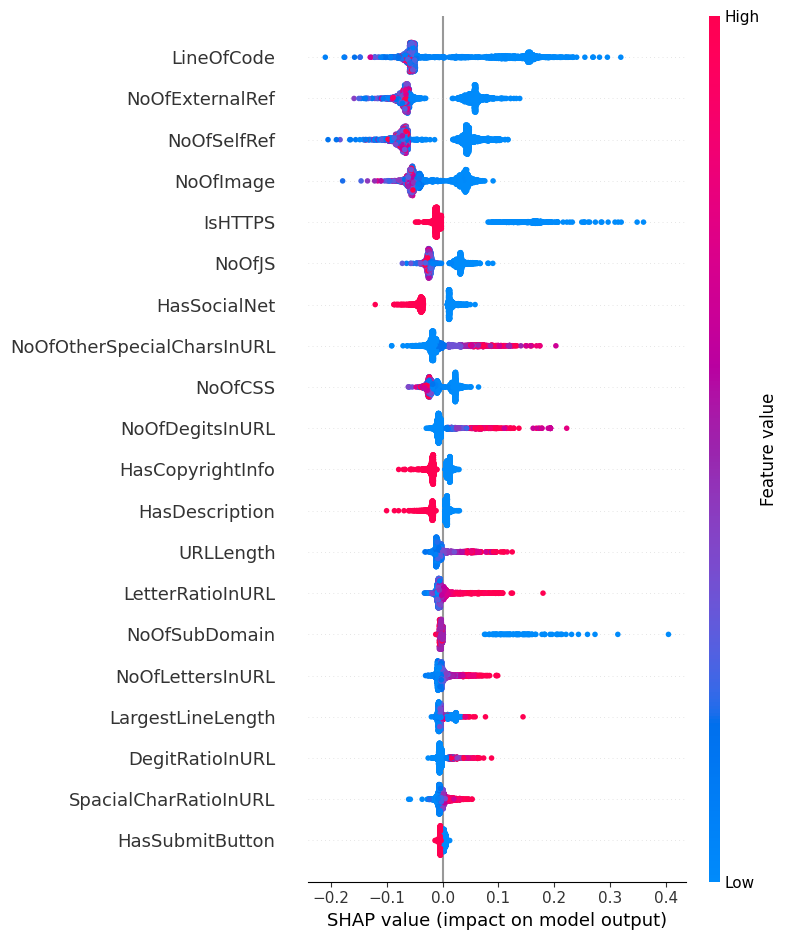


--- False Negative: index 76258 — https://www.vmailmessage.com ---


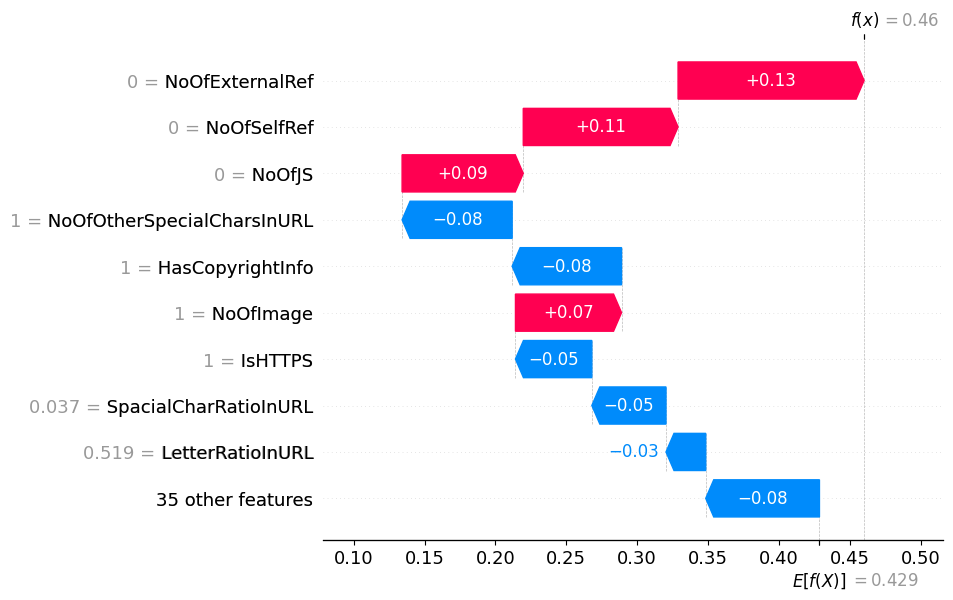


--- False Negative: index 78962 — https://www.tincanmonsters.com/ ---


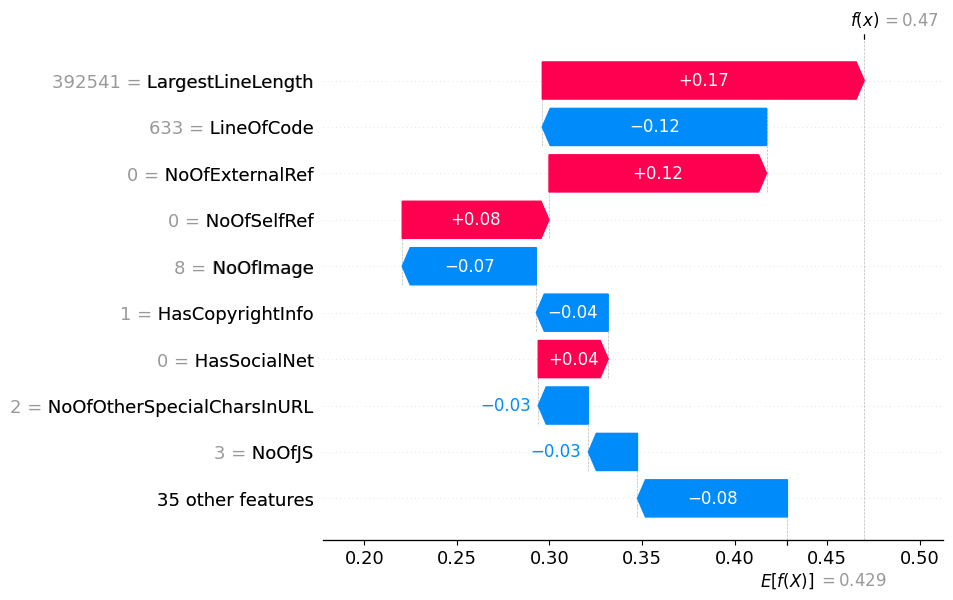


--- False Negative: index 112781 — https://byil.blogspot.com/ ---


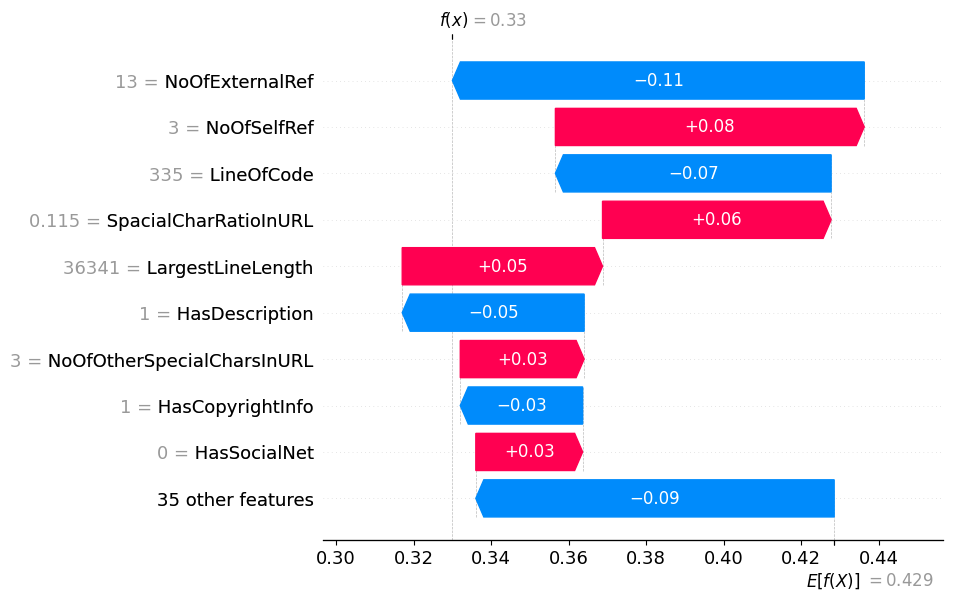


--- False Negative: index 105405 — https://www.interprocesoswebcancannovil.top/ ---


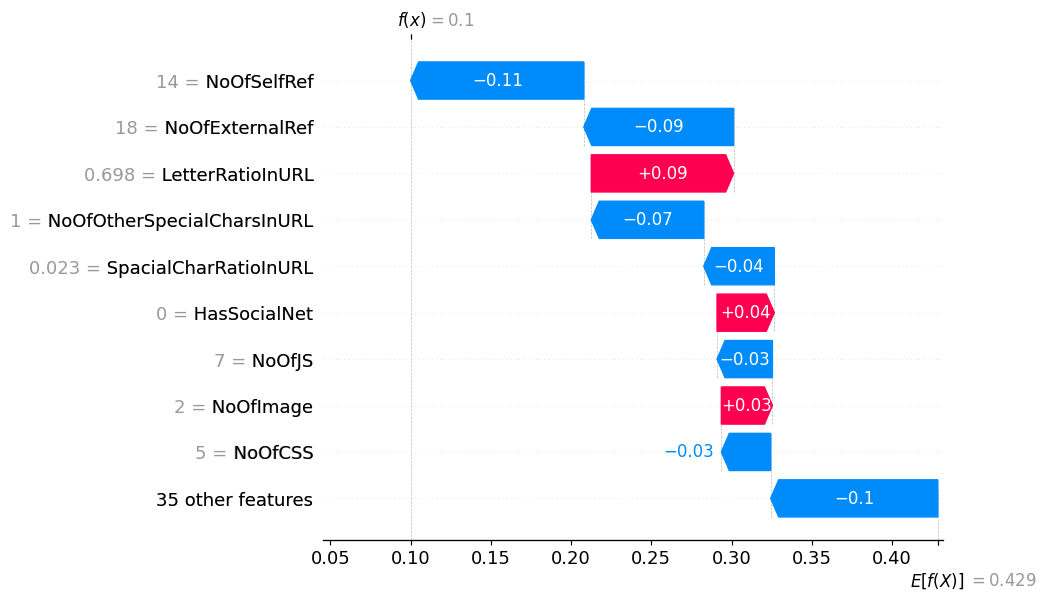


--- False Negative: index 150614 — https://pha.xujmno.xyz/logi/ ---


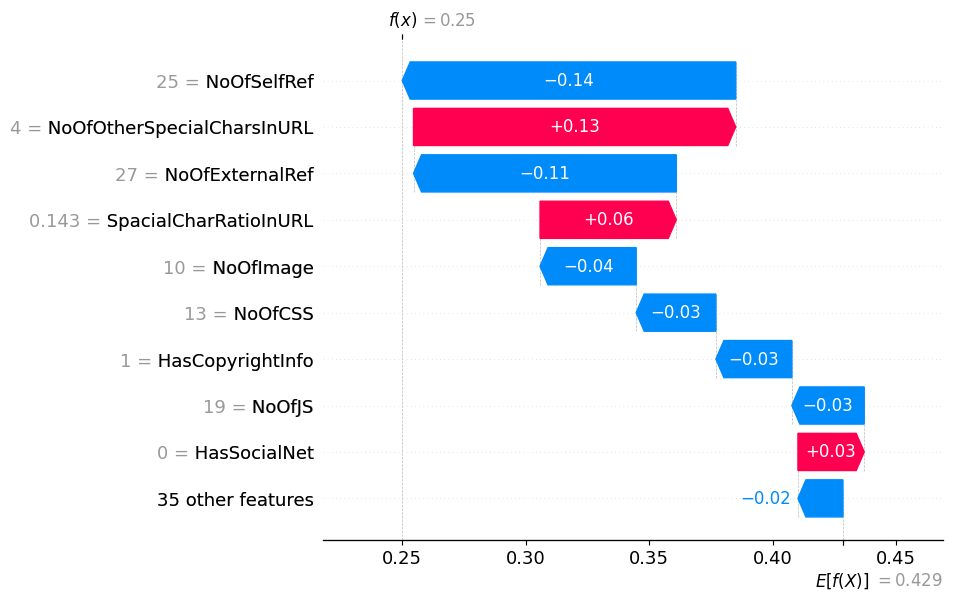


--- False Negative: index 63616 — https://www.alshayagropu.com/ ---


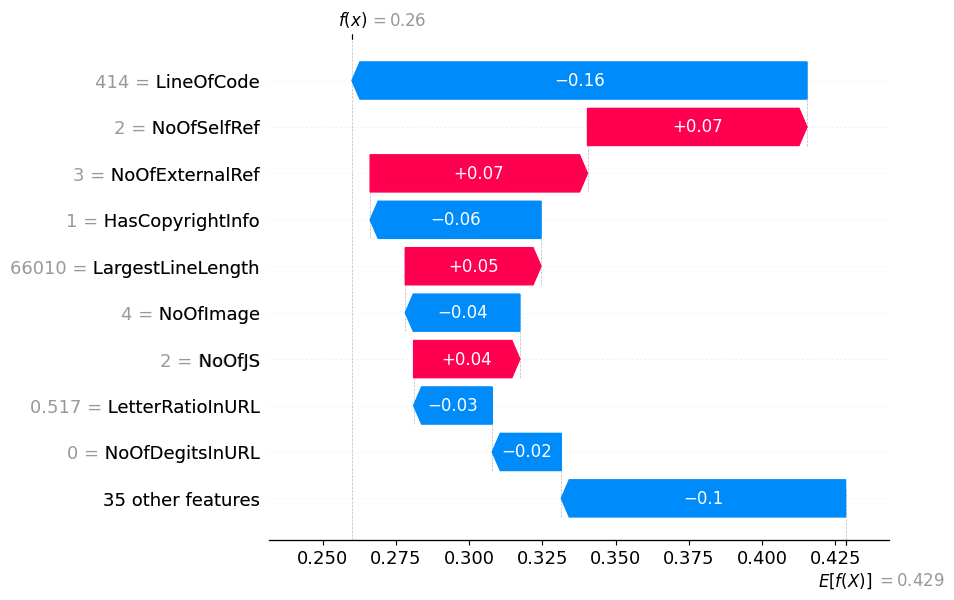


--- False Negative: index 30066 — https://www.connextsbridge.com/ ---


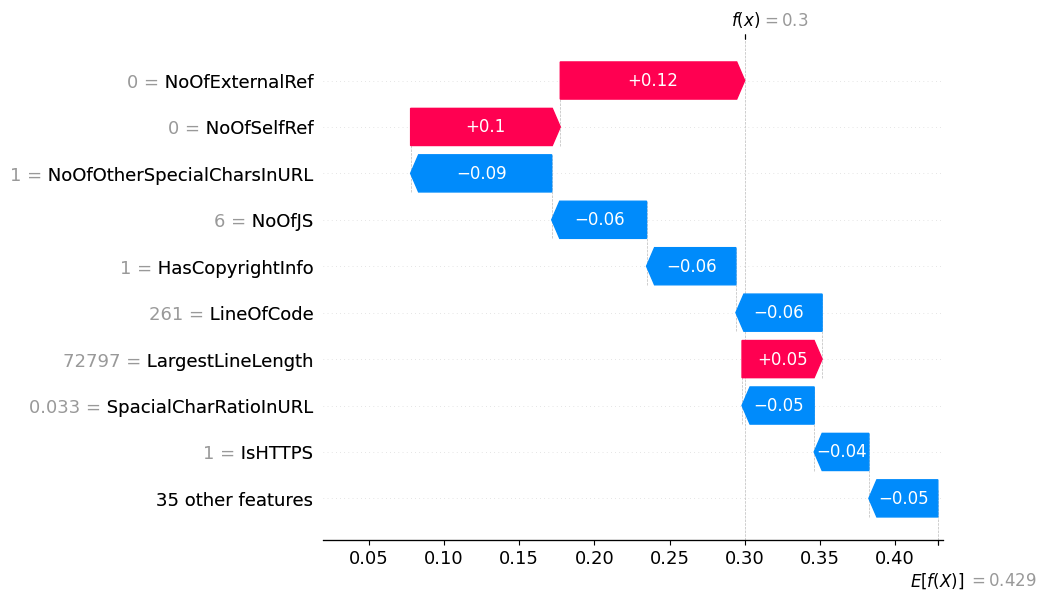


--- False Negative: index 95625 — https://www.seedjfly.top ---


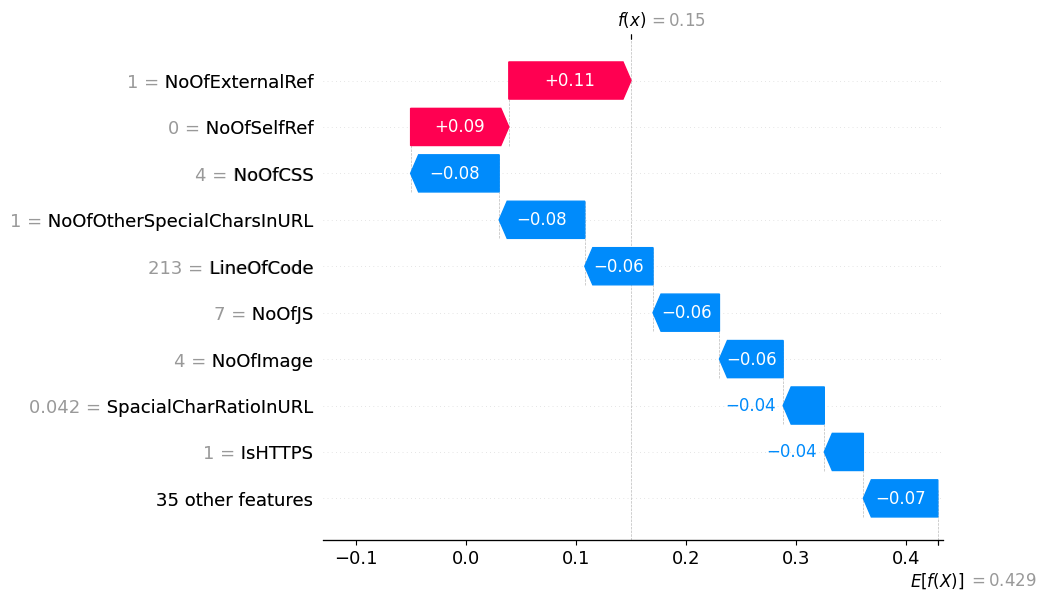


--- False Negative: index 58437 — https://www.pencakefistaking.com/ ---


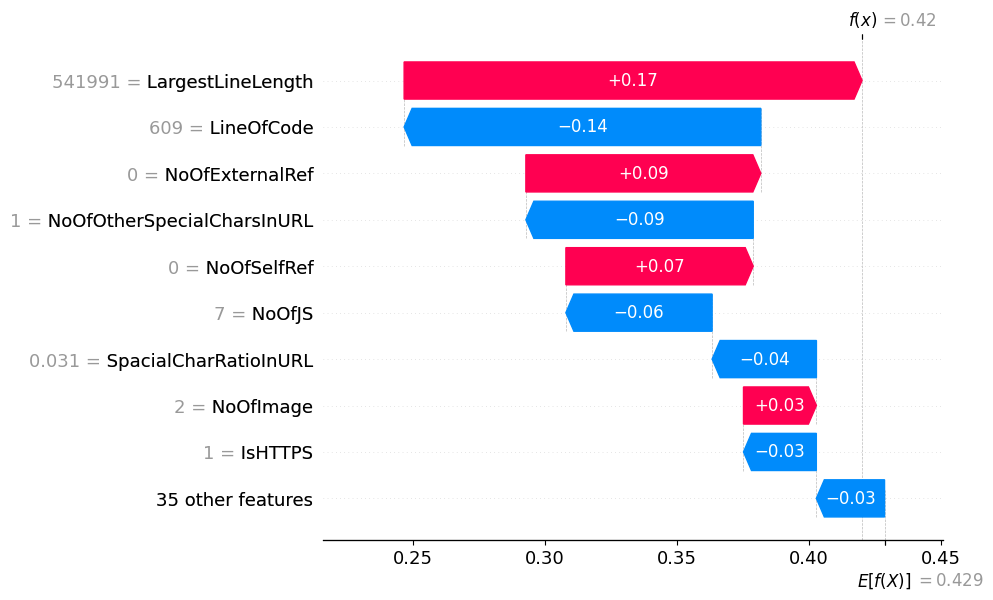


--- False Negative: index 42062 — https://binarypiano.com/ ---


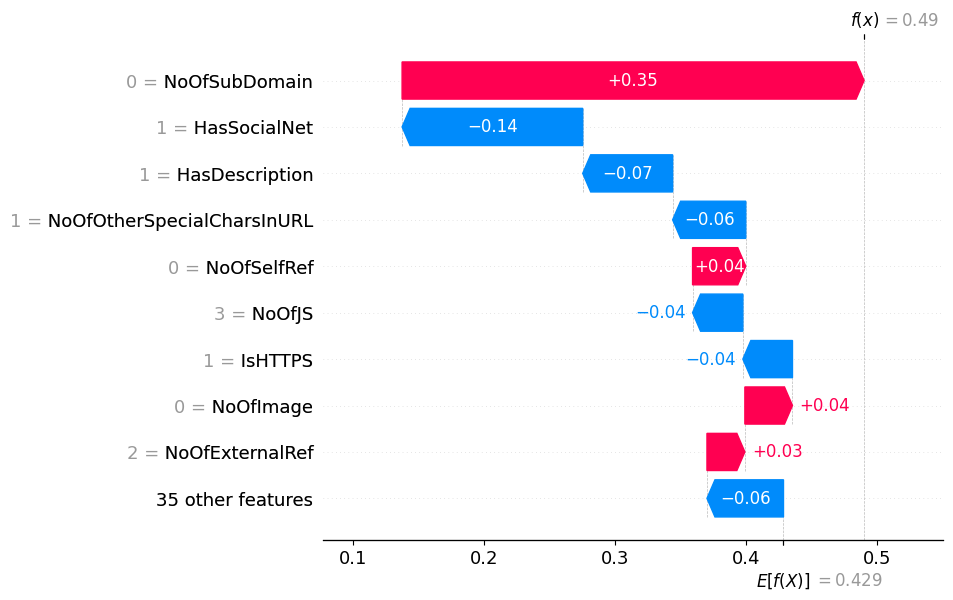


--- False Negative: index 28452 — https://rariblies.blogspot.com/ ---


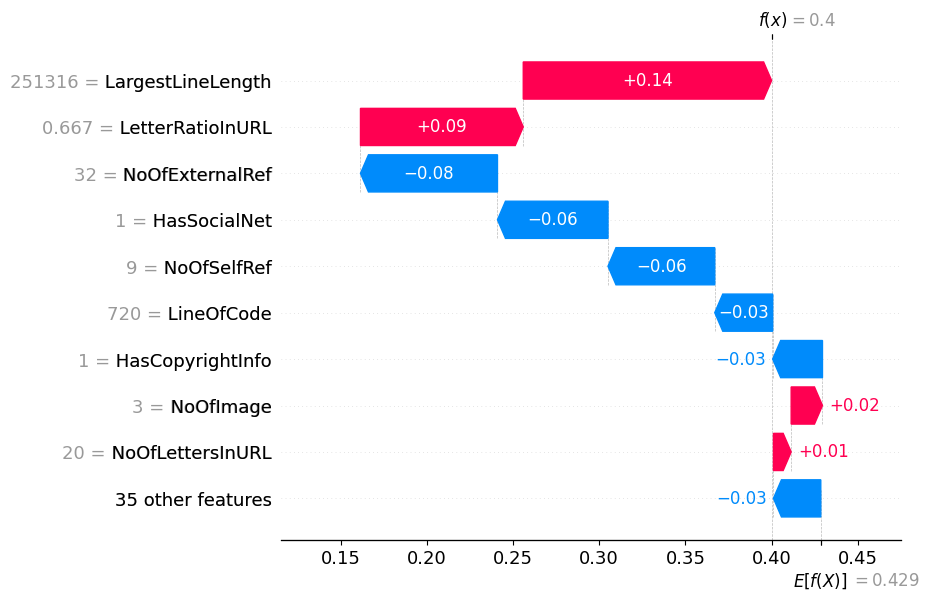


--- False Negative: index 63877 — https://www.foroarte.es/wp/privacy-policy/login.html ---


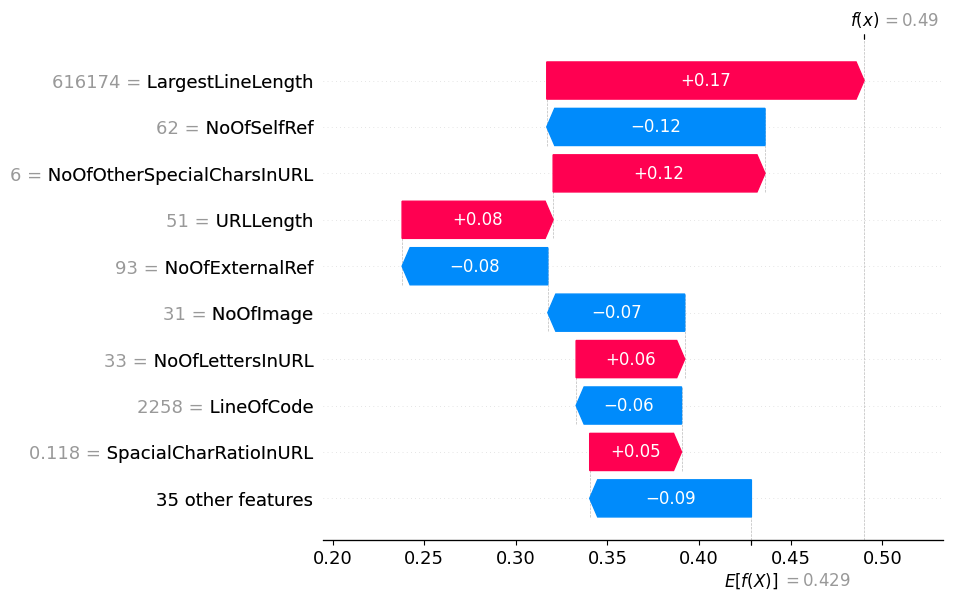

In [ ]:
import shap
X_shap_sample = X_test_web.sample(2000, random_state=35)

X_false_negatives = X_test_web.loc[fn_data.index]

# combine the random 2000-row sample with the false negatives for one explainer pass
X_shap_input = pd.concat([X_shap_sample, X_false_negatives])

explainer = shap.TreeExplainer(rf_web_pipe.named_steps['rf'])
shap_exp = explainer(X_shap_input)
shap_exp_phish = shap_exp[:, :, 1] if shap_exp.values.ndim == 3 else shap_exp

n_sample = len(X_shap_sample)

shap.summary_plot(shap_exp_phish.values[:n_sample], X_shap_sample, show=True)

for offset, idx in enumerate(X_false_negatives.index):
    print(f"\n--- False Negative: index {idx} — {data.loc[idx, 'URL']} ---")
    shap.plots.waterfall(shap_exp_phish[n_sample + offset], show=True)

**End improve hypothesis testing**

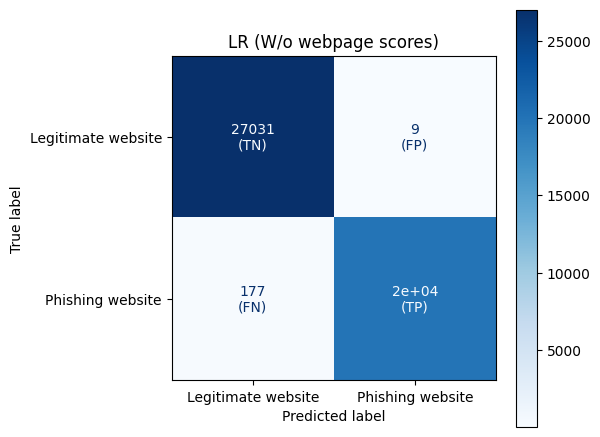

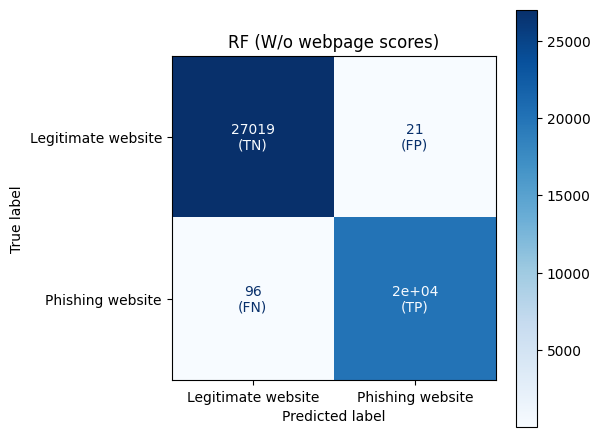

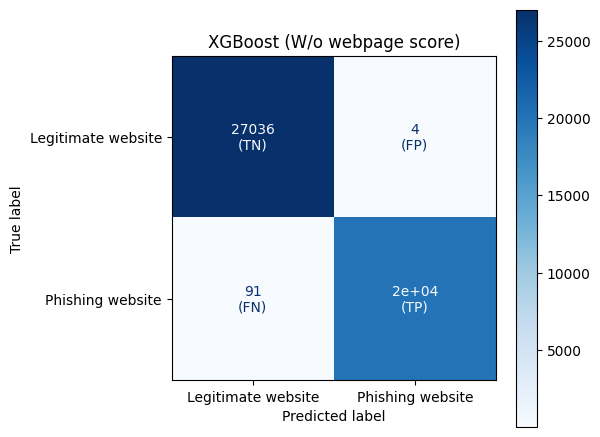

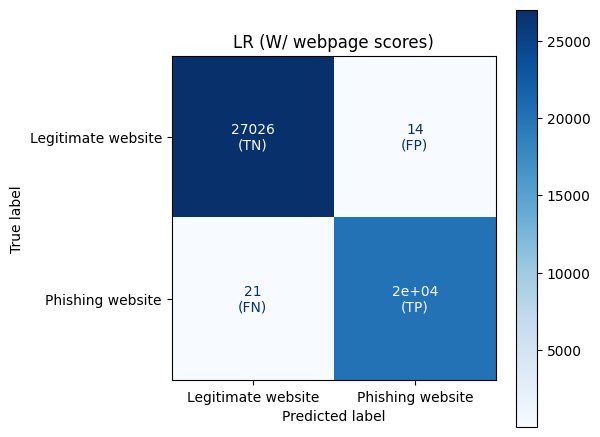

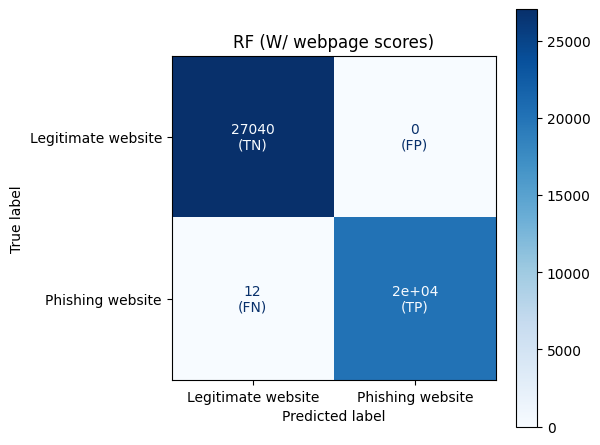

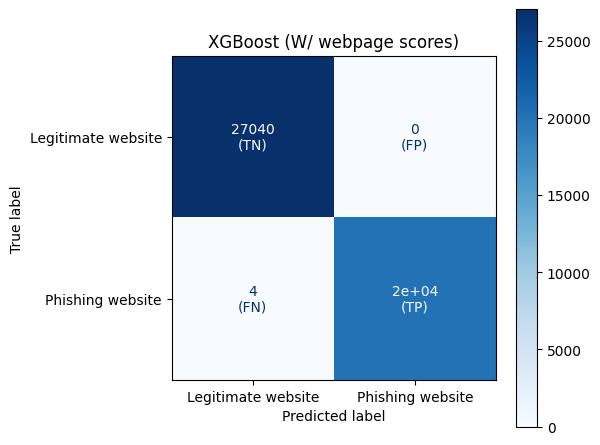

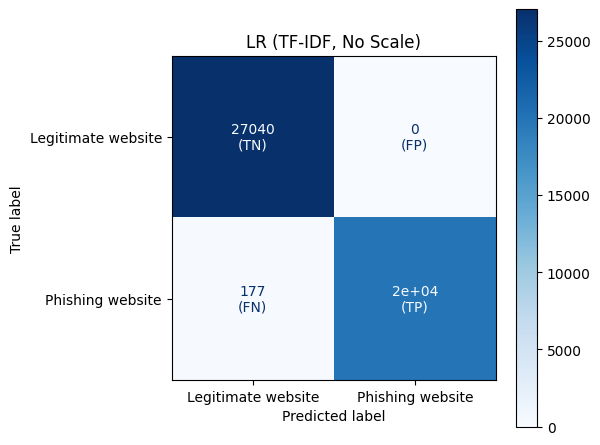

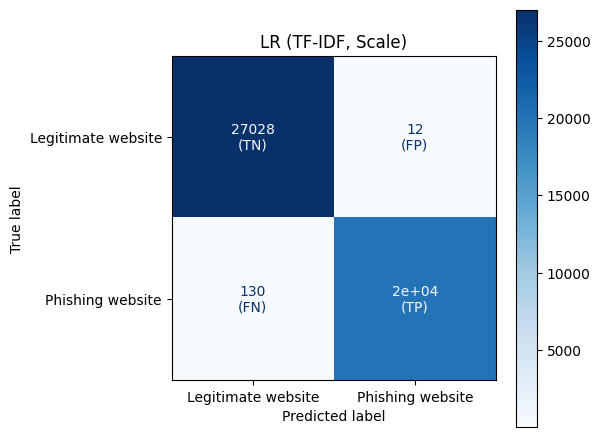

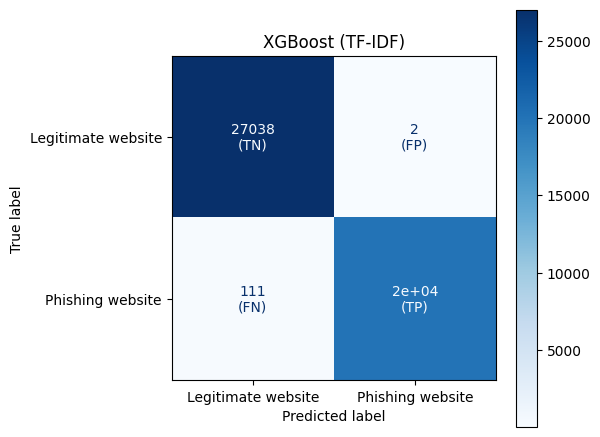

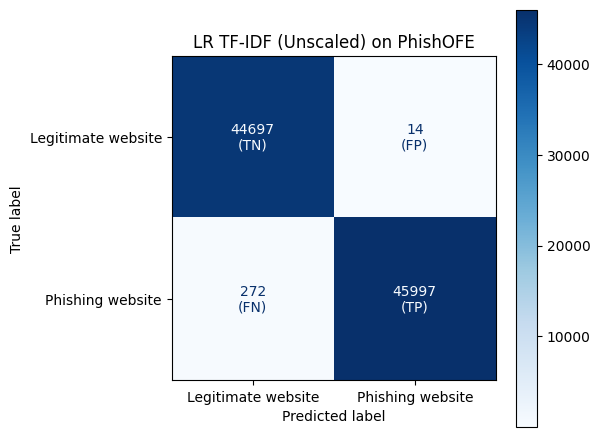

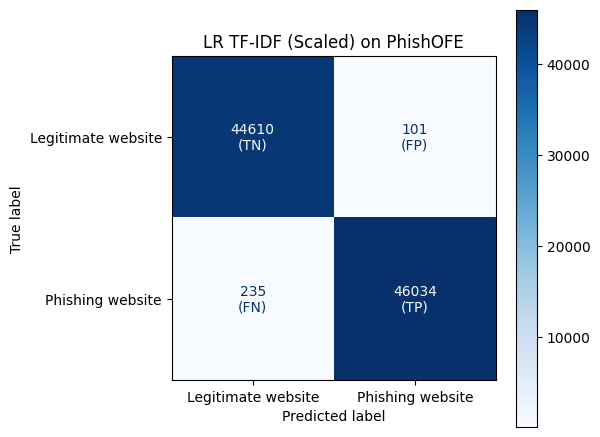

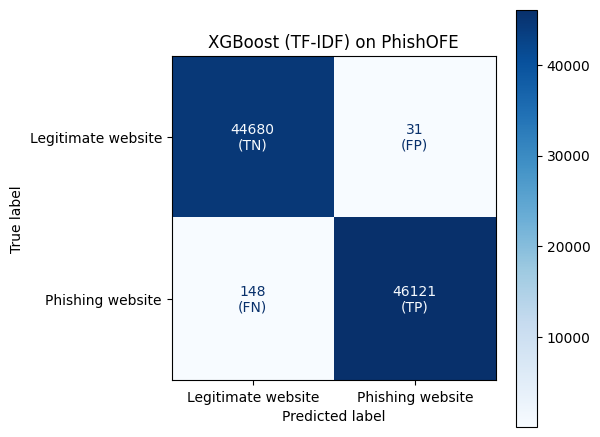

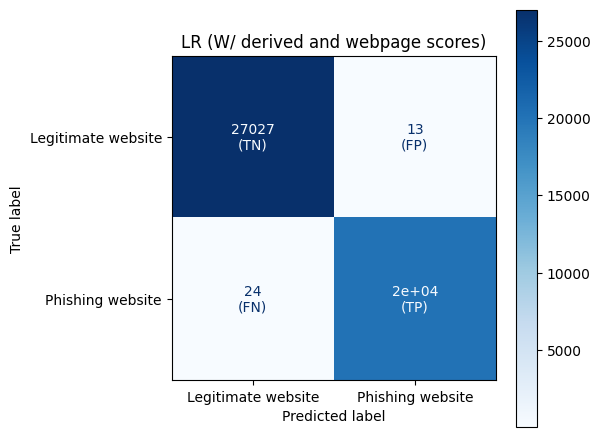

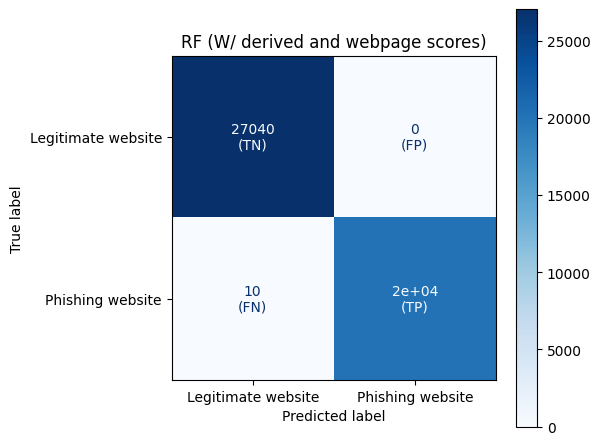

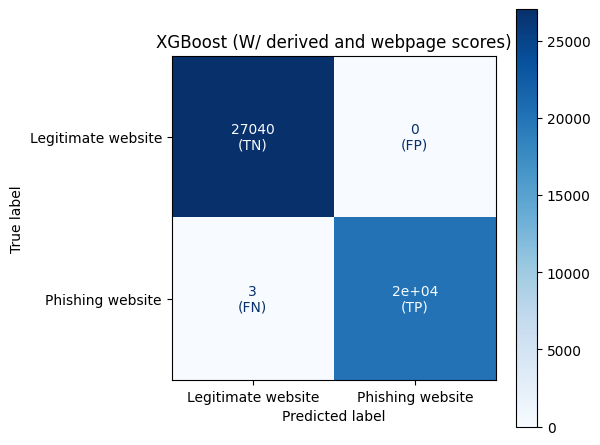

In [ ]:
# confusion matrices

plot_confusion_matrix(lr_pipe, X_test_num, y_test_num, title="LR (W/o webpage scores)")
plot_confusion_matrix(rf_pipe, X_test_num, y_test_num, title="RF (W/o webpage scores)")
plot_confusion_matrix(xgb_pipe, X_test_num, y_test_num, title="XGBoost (W/o webpage score)")

plot_confusion_matrix(lr_web_pipe, X_test_web, y_test_web, title="LR (W/ webpage scores)")
plot_confusion_matrix(rf_web_pipe, X_test_web, y_test_web, title="RF (W/ webpage scores)")
plot_confusion_matrix(xgb_web_pipe, X_test_web, y_test_web, title="XGBoost (W/ webpage scores)")

plot_confusion_matrix(pipe_char_no_scale, X_test_url, y_test_url, title="LR (TF-IDF, No Scale)")
plot_confusion_matrix(pipe_char, X_test_url, y_test_url, title="LR (TF-IDF, Scale)")
plot_confusion_matrix(pipe_xgb_char, X_test_url, y_test_url, title="XGBoost (TF-IDF)")

plot_confusion_matrix(pipe_char_no_scale, X_phishofe_clean, y_phishofe_clean, title="LR TF-IDF (Unscaled) on PhishOFE")
plot_confusion_matrix(pipe_char, X_phishofe_clean, y_phishofe_clean, title="LR TF-IDF (Scaled) on PhishOFE")
plot_confusion_matrix(pipe_xgb_char, X_phishofe_clean, y_phishofe_clean, title="XGBoost (TF-IDF) on PhishOFE")

plot_confusion_matrix(lr_all_pipe, X_test_all, y_test_all, title="LR (W/ derived and webpage scores)")
plot_confusion_matrix(rf_all_pipe, X_test_all, y_test_all, title="RF (W/ derived and webpage scores)")
plot_confusion_matrix(xgb_all_pipe, X_test_all, y_test_all, title="XGBoost (W/ derived and webpage scores)")

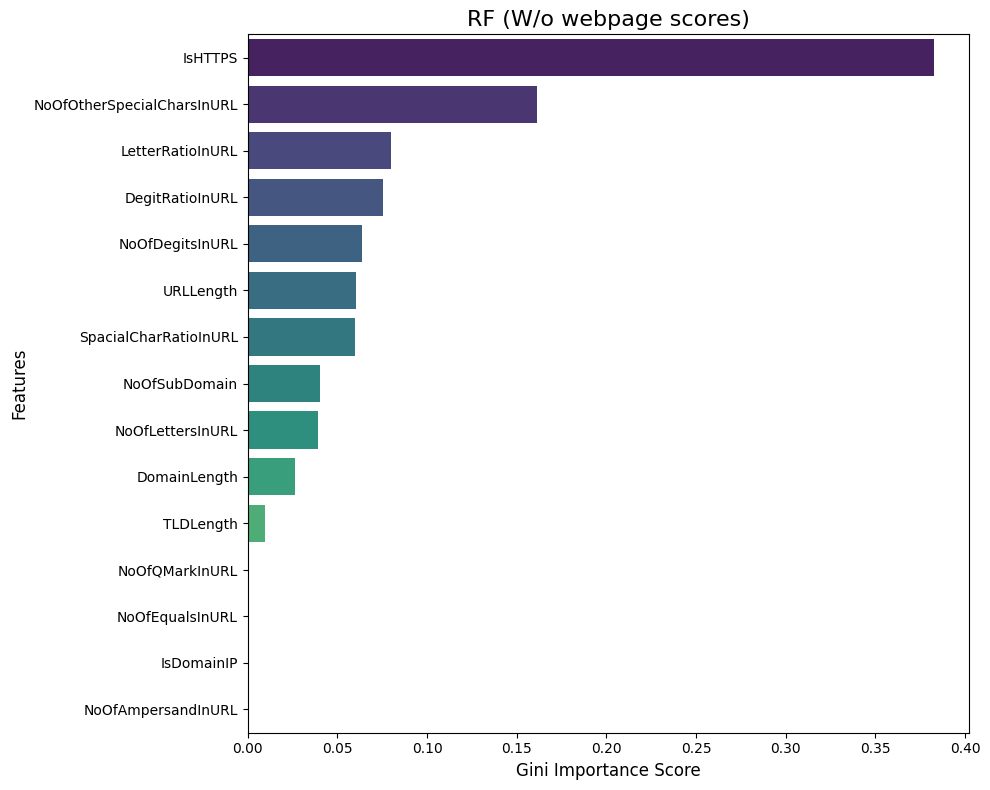

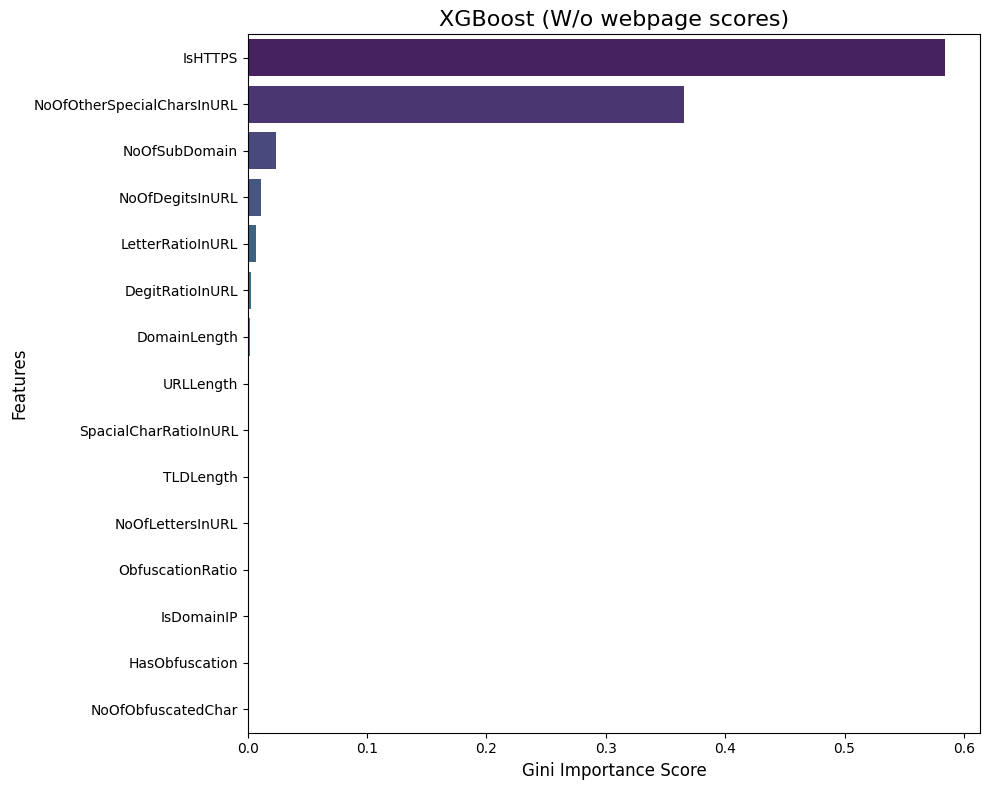

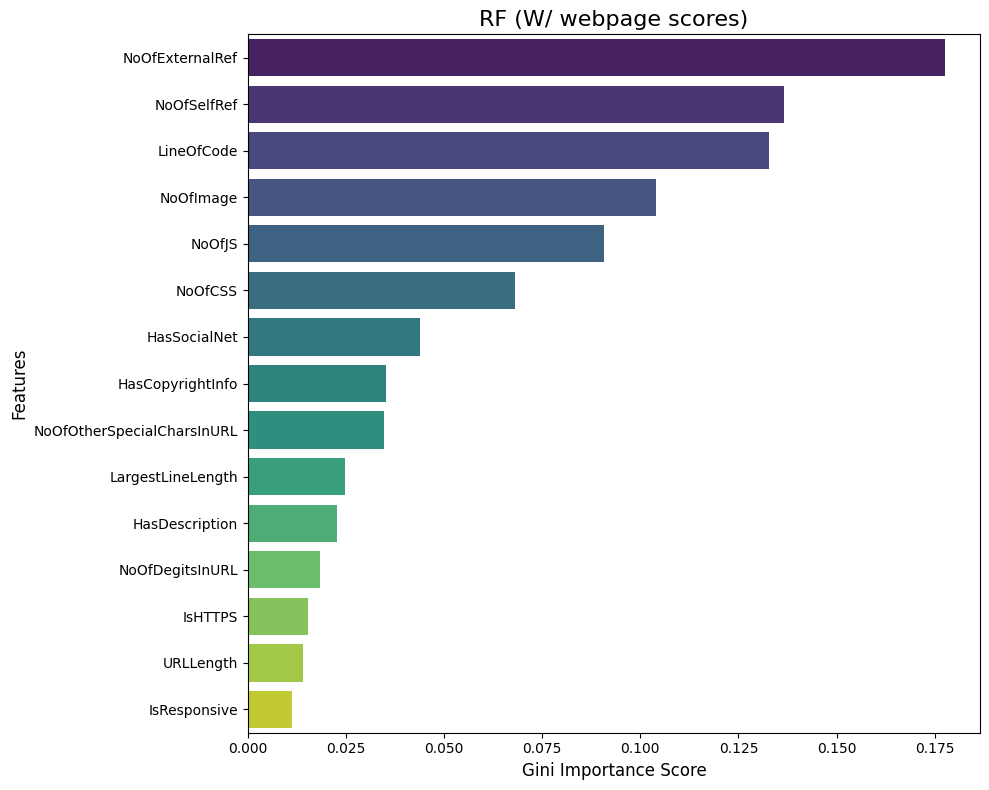

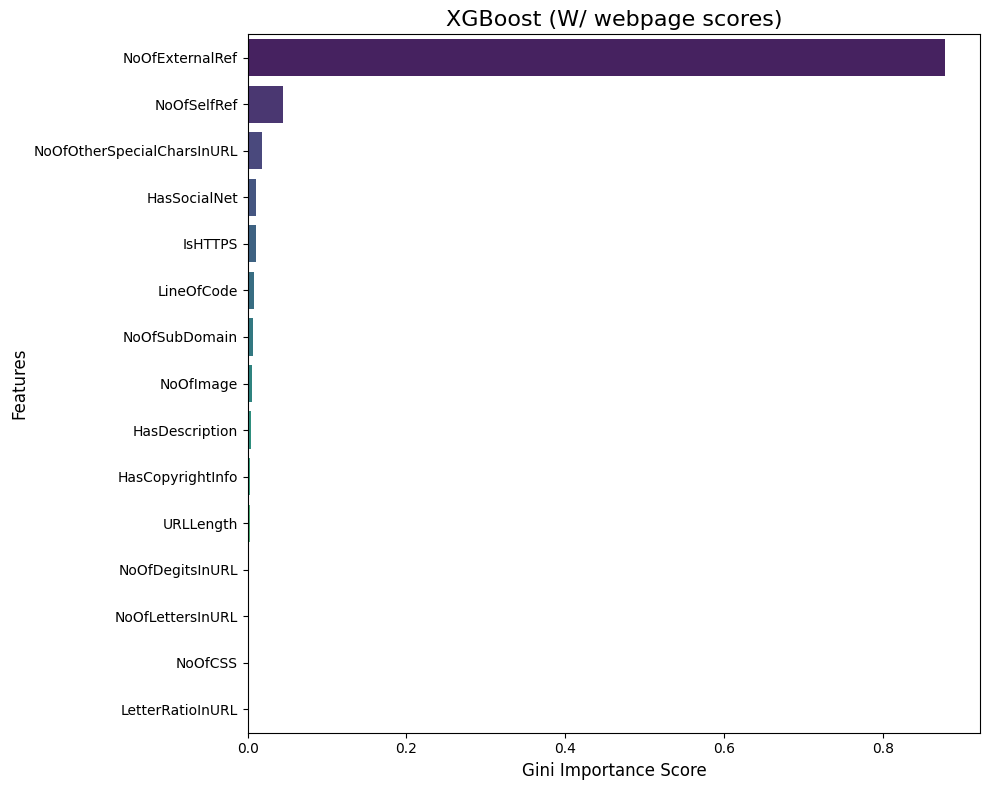

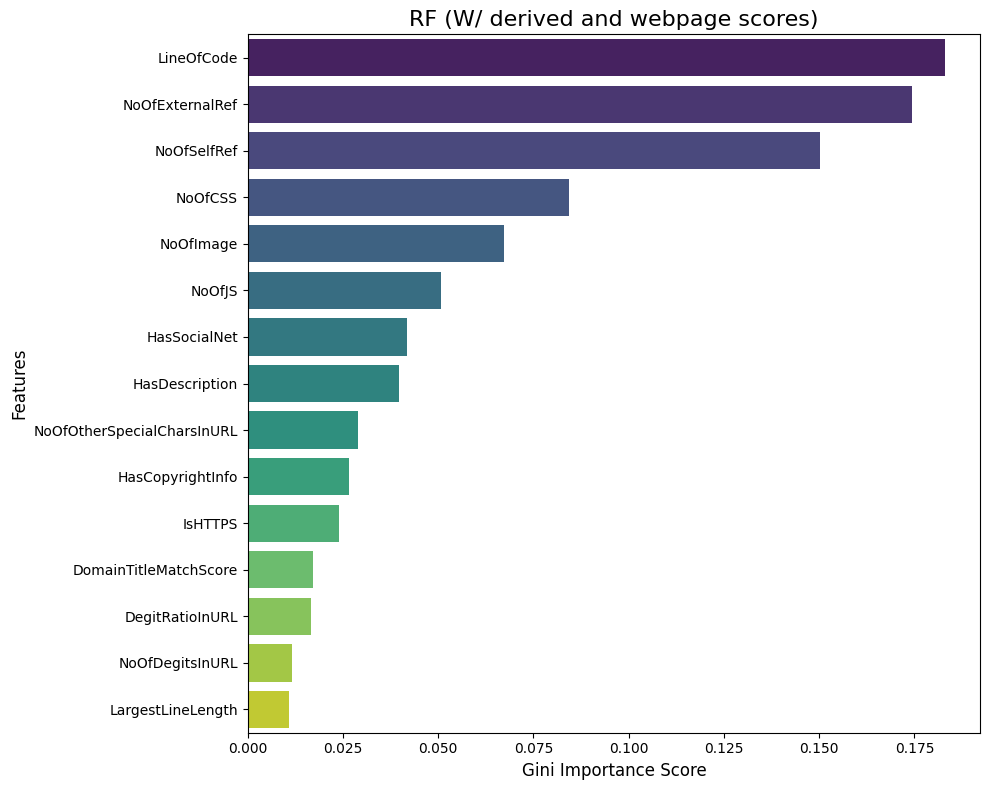

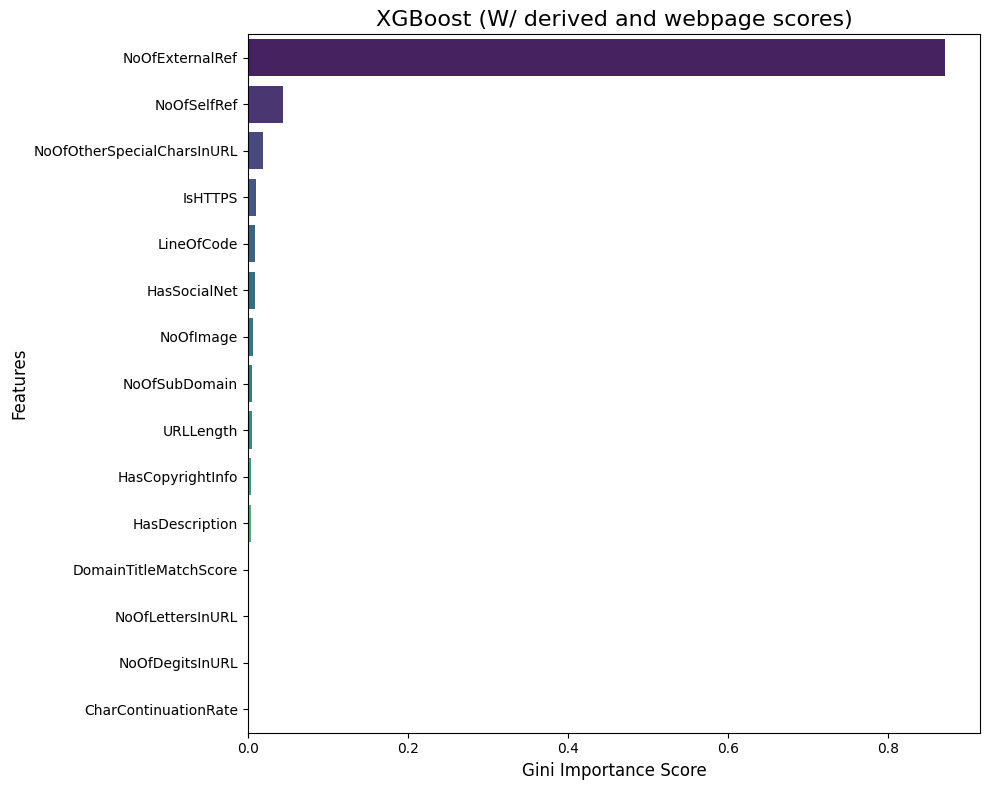

In [ ]:
# RF feature importance graphs

plot_top_features(rf_pipe, X_train_num, title="RF (W/o webpage scores)")
plot_top_features(xgb_pipe, X_train_num, model_step_name='xgb', title="XGBoost (W/o webpage scores)")
plot_top_features(rf_web_pipe, X_train_web, title="RF (W/ webpage scores)")
plot_top_features(xgb_web_pipe, X_train_web, model_step_name='xgb', title="XGBoost (W/ webpage scores)")
plot_top_features(rf_all_pipe, X_train_all, title="RF (W/ derived and webpage scores)")
plot_top_features(xgb_all_pipe, X_train_all, model_step_name='xgb', title="XGBoost (W/ derived and webpage scores)")